# EDA de corpus paralelo para NLP — `Corpus_Recopilado.xlsx`

Análisis exploratorio de un corpus **Español ↔ Quechua Chanka** repartido en **varias hojas** de un mismo libro de Excel
(cada hoja es un subcorpus/dominio; cada fila es un par de oraciones alineadas).

**Índice**

0. Configuración y carga
1. Estructura de las hojas y unificación del corpus
2. Calidad de datos (vacíos, duplicados, pares incompletos o sin traducir)
3. Estadísticas básicas de longitud
4. Alineación del corpus paralelo (relación de longitudes entre idiomas)
5. Ruido textual e inventario de caracteres
6. Normalización y tokenización
7. Vocabulario (tokens, tipos, TTR, hapax, ley de Zipf)
8. Palabras más frecuentes
9. N-gramas
10. Comparación entre hojas y entre idiomas
11. Proyección 2D (TF-IDF + SVD)
12. Distribución de etiquetas (si existe)
13. Análisis lingüístico opcional con spaCy
14. Hallazgos y exportación

> **Cómo usarlo:** ajusta solo la celda de configuración (sección 0) y ejecuta de arriba hacia abajo.
> Los análisis léxicos (secciones 6–11) se hacen **por separado para cada idioma**, porque mezclar español y quechua en un mismo vocabulario no tendría sentido.

## 0. Configuración y carga

In [1]:
# Descomenta si te falta alguna librería:
# %pip install pandas openpyxl numpy matplotlib seaborn scikit-learn nltk wordcloud

In [2]:
import sys
from pathlib import Path
if (Path.cwd() / '.eda_deps').is_dir():
    sys.path.insert(0, str(Path.cwd() / '.eda_deps'))
import re
import textwrap
import unicodedata
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

# Se conservan las advertencias para detectar problemas de reproducibilidad.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [3]:
# ============================ CONFIGURACIÓN (ajusta aquí) ============================
RUTA_EXCEL = "Corpus_Recopilado.xlsx"

HOJAS = None        # None = todas las hojas  |  o una lista: ["Hoja1", "Hoja2"]

# Una entrada por idioma:  "nombre de la columna en el Excel": "idioma de stopwords NLTK" (o None)
# El nombre de la columna se usa también como nombre del idioma en tablas y gráficos.
# Para un corpus monolingüe basta con dejar una sola entrada.
COLS_TEXTO = {
    "Español":        "spanish",
    "Quechua Chanka": None,          # NLTK no trae stopwords de quechua
}

# Stopwords adicionales por idioma (p. ej. tras revisar las palabras más frecuentes en la sección 8)
STOPWORDS_EXTRA = {
    "Quechua Chanka": [],            # ej.: ["kay", "chay"]
}

COL_ETIQUETA = None  # nombre de una columna de categoría (opcional)

ELIMINAR_INCOMPLETOS = True   # quita pares donde falta el texto de algún idioma
ELIMINAR_DUPLICADOS  = True   # quita pares repetidos (mismo texto en TODOS los idiomas)
MIN_PALABRAS_CORTO   = 2      # umbral para marcar textos "muy cortos" (en palabras)
MIN_LETRAS_TOKEN     = 2      # longitud mínima de token en el análisis léxico
TOP_N                = 20     # tamaño de los rankings
MAX_DOCS_PROYECCION  = 3000   # máximo de documentos en la proyección 2D

USAR_SPACY    = False                          # activa la sección 13
MODELOS_SPACY = {"Español": "es_core_news_sm"}  # no existe modelo spaCy de quechua
SEMILLA       = 42
# =====================================================================================

In [4]:
import hashlib, json, platform
from datetime import datetime, timezone
from importlib.metadata import version
N_SELECCION = 300
MIN_ES_SELECCION, MAX_ES_SELECCION = 3, 12
MAX_QU_SELECCION = 25
REPETICIONES_COBERTURA = 20
RUTA_REFERENCIA = Path('flashcards.xlsx')
SALIDA = Path('resultados_vibe') / datetime.now(timezone.utc).strftime('revision_%Y%m%dT%H%M%S_%fZ')
SALIDA.mkdir(parents=True, exist_ok=False)
fuentes = [Path(RUTA_EXCEL), RUTA_REFERENCIA]
inventario_entrada = {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in fuentes}
print('Salida nueva de esta ejecución:', SALIDA)


Salida nueva de esta ejecución: resultados_vibe\revision_20261013T234825_221182Z


In [5]:
# Carga de TODAS las hojas en un diccionario {nombre_hoja: DataFrame}
dict_hojas = pd.read_excel(RUTA_EXCEL, sheet_name=HOJAS, engine="openpyxl")
for d in dict_hojas.values():
    d.columns = d.columns.astype(str).str.strip()      # quita espacios sobrantes en los encabezados
print(f"Hojas cargadas: {list(dict_hojas.keys())}")

Hojas cargadas: ['Grupo 1 - Principito', 'Grupo 2 - Corpus Chanka', 'Grupo 3 - Corpus Medico']


## 1. Estructura de las hojas y unificación del corpus

Se comprueba que cada hoja tenga las columnas de texto configuradas y se arma:

- `pares`: formato **ancho** (una fila por par, una columna por idioma).
- `corpus`: formato **largo** (una fila por texto, con la columna `idioma`), que es el que usan los análisis léxicos.

Al unificar se aplica normalización Unicode **NFC** (evita que una «ñ» o una tilde se descompongan en dos caracteres)
y se unifican las variantes de apóstrofo (’ ‘ ´ ʼ → '), importantes en quechua.

In [6]:
resumen = pd.DataFrame({
    "hoja": list(dict_hojas),
    "filas": [d.shape[0] for d in dict_hojas.values()],
    "columnas": [d.shape[1] for d in dict_hojas.values()],
    "nombres_columnas": [", ".join(map(str, d.columns)) for d in dict_hojas.values()],
})
display(resumen)

for nombre, d in dict_hojas.items():
    print(f"\n=== {nombre} ===")
    display(d.head(3))

# Validación: todas las hojas deben tener las columnas de texto configuradas
faltantes = {h: [c for c in COLS_TEXTO if c not in d.columns] for h, d in dict_hojas.items()}
faltantes = {h: c for h, c in faltantes.items() if c}
if faltantes:
    raise KeyError(f"Faltan columnas de texto en estas hojas: {faltantes}. "
                   f"Columnas disponibles: { {h: list(d.columns) for h, d in dict_hojas.items()} }")

,hoja,filas,columnas,nombres_columnas
0,Grupo 1 - Principito,113,3,"N°, Español, Quechua Chanka"
1,Grupo 2 - Corpus Chanka,676,3,"N°, Español, Quechua Chanka"
2,Grupo 3 - Corpus Medico,685,3,"N°, Español, Quechua Chanka"



=== Grupo 1 - Principito ===


,N°,Español,Quechua Chanka
0,EL-0001,Pido perdón a los niños por haber dedicado este libro a una persona mayor.,Machu runaman kay librota qusqaymanta wawakunata pampachaykuwanaykichikpaq mañakuykichik.
1,EL-0002,Tengo una muy seria disculpa,Ancha allin pampachaykuwayniymi kachkan
2,EL-0003,Esta persona mayor es el mejor amigo que tengo en el mundo.,Kay machu runaqa allin amistadniymi kay pachapi.



=== Grupo 2 - Corpus Chanka ===


,N°,Español,Quechua Chanka
0,F-0001,El niño va corriendo a la chacra.,Qari warma chakraman kallpaspa rin.
1,F-0002,El niño está corriendo en la chacra.,Qari warma chakrapi kallpachkan.
2,F-0003,La mujer canta una canción.,Warmi huk takita takin.



=== Grupo 3 - Corpus Medico ===


,N°,Español,Quechua Chanka
0,1.000,¿Cómo estás?,¿Imaynam kachkanki?
1,2.000,No estoy bien.,Manam allinchu kani.
2,3.000,¿Qué te duele?,¿Imaykitaq nanasunki?


In [7]:
IDIOMAS = list(COLS_TEXTO)

APOSTROFES = str.maketrans({"’": "'", "‘": "'", "´": "'", "`": "'", "ʼ": "'"})

def normalizar_unicode(t):
    if pd.isna(t):
        return t
    return unicodedata.normalize("NFC", str(t)).translate(APOSTROFES)

partes, cambios = [], Counter()
for hoja, d in dict_hojas.items():
    p = pd.DataFrame({"hoja": hoja, "fila_excel": d.index + 2})     # +2: encabezado en fila 1 y base 1 de Excel
    p['codigo_original'] = d['N°'].astype('string').fillna('') if 'N°' in d else ''
    p['par_id'] = [f'{hoja}:fila_{i}' for i in p['fila_excel']]
    for idioma in IDIOMAS:
        original = d[idioma]
        p[f"{idioma}__original"] = original
        p[idioma] = original.map(normalizar_unicode)
        cambios[idioma] += int((original.astype("string").fillna("") != p[idioma].astype("string").fillna("")).sum())
    if COL_ETIQUETA:
        p["etiqueta"] = d[COL_ETIQUETA].values
    partes.append(p)

pares = pd.concat(partes, ignore_index=True)
print(f"Pares unificados: {len(pares):,}  |  idiomas: {IDIOMAS}")
print(f"Textos modificados por la normalización Unicode/apóstrofos: {dict(cambios)}")
pares.head()

Pares unificados: 1,474  |  idiomas: ['Español', 'Quechua Chanka']
Textos modificados por la normalización Unicode/apóstrofos: {'Español': 0, 'Quechua Chanka': 0}


,hoja,fila_excel,codigo_original,par_id,Español__original,Español,Quechua Chanka__original,Quechua Chanka
0,Grupo 1 - Principito,2,EL-0001,Grupo 1 - Principito:fila_2,Pido perdón a los niños por haber dedicado este libro a una persona mayor.,Pido perdón a los niños por haber dedicado este libro a una persona mayor.,Machu runaman kay librota qusqaymanta wawakunata pampachaykuwanaykichikpaq mañakuykichik.,Machu runaman kay librota qusqaymanta wawakunata pampachaykuwanaykichikpaq mañakuykichik.
1,Grupo 1 - Principito,3,EL-0002,Grupo 1 - Principito:fila_3,Tengo una muy seria disculpa,Tengo una muy seria disculpa,Ancha allin pampachaykuwayniymi kachkan,Ancha allin pampachaykuwayniymi kachkan
2,Grupo 1 - Principito,4,EL-0003,Grupo 1 - Principito:fila_4,Esta persona mayor es el mejor amigo que tengo en el mundo.,Esta persona mayor es el mejor amigo que tengo en el mundo.,Kay machu runaqa allin amistadniymi kay pachapi.,Kay machu runaqa allin amistadniymi kay pachapi.
3,Grupo 1 - Principito,5,EL-0004,Grupo 1 - Principito:fila_5,Tengo otra disculpa,Tengo otra disculpa,Huk pampachaykuwayniymi kachkan,Huk pampachaykuwayniymi kachkan
4,Grupo 1 - Principito,6,EL-0005,Grupo 1 - Principito:fila_6,"Esta persona mayor es capaz de comprender todo, hasta los libros para niños.","Esta persona mayor es capaz de comprender todo, hasta los libros para niños.","Kay machu runaqa lliwtam entienden, warmakunapaq qillqakunatapas.","Kay machu runaqa lliwtam entienden, warmakunapaq qillqakunatapas."


## 2. Calidad de datos

En un corpus paralelo la unidad de limpieza es el **par**, no el texto suelto: si se borra solo un lado, el otro queda huérfano.
Se revisan:

- textos **vacíos** (par incompleto);
- pares **duplicados** (mismo texto en todos los idiomas);
- pares con **texto idéntico en ambos idiomas** (posible oración sin traducir);
- textos de origen **repetidos con traducciones distintas** (normal en traducción, pero conviene saberlo).

In [8]:
def norm_texto(s):
    return s.fillna("").astype(str).str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

COLS_NORM = []
for idioma in IDIOMAS:
    pares[f"{idioma}__norm"] = norm_texto(pares[idioma])
    COLS_NORM.append(f"{idioma}__norm")

pares["incompleto"] = pares[COLS_NORM].eq("").any(axis=1)
pares["duplicado"]  = (~pares["incompleto"]) & pares.duplicated(subset=COLS_NORM, keep="first")

if len(IDIOMAS) >= 2:
    A, B = IDIOMAS[:2]
    pares["identico"] = (~pares["incompleto"]) & (pares[f"{A}__norm"] == pares[f"{B}__norm"])
else:
    pares["identico"] = False

# --- vacíos por idioma y hoja
vacios = pd.DataFrame({idioma: pares[f"{idioma}__norm"].eq("").groupby(pares["hoja"]).sum()
                       for idioma in IDIOMAS}).add_prefix("vacíos · ")

calidad = pares.groupby("hoja").agg(
    pares=("fila_excel", "size"),
    incompletos=("incompleto", "sum"),
    duplicados=("duplicado", "sum"),
    identicos_A_B=("identico", "sum"),
).join(vacios)
calidad["% incompletos"] = 100 * calidad["incompletos"] / calidad["pares"]
calidad["% duplicados"]  = 100 * calidad["duplicados"] / calidad["pares"]
display(calidad)

,pares,incompletos,duplicados,identicos_A_B,vacíos · Español,vacíos · Quechua Chanka,% incompletos,% duplicados
hoja,,,,,,,,
Grupo 1 - Principito,113,0,0,0,0,0,0.000,0.000
Grupo 2 - Corpus Chanka,676,7,2,0,7,4,1.036,0.296
Grupo 3 - Corpus Medico,685,2,2,0,0,2,0.292,0.292


In [9]:
# Ejemplos de lo detectado
for nombre, mascara in [("Pares incompletos", pares["incompleto"]),
                        ("Pares duplicados", pares["duplicado"]),
                        ("Pares con texto idéntico en ambos idiomas", pares["identico"])]:
    print(f"\n{nombre}: {int(mascara.sum())}")
    if mascara.any():
        display(pares.loc[mascara, ["hoja", "fila_excel", *IDIOMAS]].head(8))


Pares incompletos: 9


,hoja,fila_excel,Español,Quechua Chanka
639,Grupo 2 - Corpus Chanka,528,NaN,NaN
783,Grupo 2 - Corpus Chanka,672,NaN,NaN
784,Grupo 2 - Corpus Chanka,673,NaN,NaN
785,Grupo 2 - Corpus Chanka,674,NaN,NaN
786,Grupo 2 - Corpus Chanka,675,NaN,Referencias
787,Grupo 2 - Corpus Chanka,676,NaN,Ministerio de Educación (2014). Yachakuqkunapa simi qullqa: Ayakuchu Chanka Qichwa simipi. Lima:...
788,Grupo 2 - Corpus Chanka,677,NaN,Ministerio de Educación (2021). Urin qichwa qillqay yachana mayt'u: Manual de escritura quechua ...
1007,Grupo 3 - Corpus Medico,220,Quítate los pantalones,NaN



Pares duplicados: 4


,hoja,fila_excel,Español,Quechua Chanka
483,Grupo 2 - Corpus Chanka,372,tú te lavas las manos con agua.,Qam yakuwan makiykita mayllakunki.
571,Grupo 2 - Corpus Chanka,460,mamá cocina pescado.,Mamay challwata yanun.
815,Grupo 3 - Corpus Medico,28,¿Qué te duele?,¿Imaykitaq nanasunki?
834,Grupo 3 - Corpus Medico,47,¿Qué te duele?,¿Imaykitaq nanasunki?



Pares con texto idéntico en ambos idiomas: 0


In [10]:
# Duplicados ENTRE hojas y relaciones uno-a-muchos (informativo, no se elimina nada aquí)
completos = pares[~pares["incompleto"]]

hojas_por_par = completos.groupby(COLS_NORM)["hoja"].nunique()
print(f"Pares presentes en más de una hoja: {int((hojas_por_par > 1).sum())}")

if len(IDIOMAS) >= 2:
    a, b = COLS_NORM[:2]
    a_multi = completos.groupby(a)[b].nunique()
    b_multi = completos.groupby(b)[a].nunique()
    print(f"Textos en {IDIOMAS[0]} con más de una traducción distinta:  {int((a_multi > 1).sum())}")
    print(f"Textos en {IDIOMAS[1]} con más de una versión distinta:     {int((b_multi > 1).sum())}")

    ejemplos = a_multi[a_multi > 1].sort_values(ascending=False).head(5).index
    if len(ejemplos):
        display(completos[completos[a].isin(ejemplos)].sort_values(a)[["hoja", "fila_excel", *IDIOMAS[:2]]].head(12))

Pares presentes en más de una hoja: 0
Textos en Español con más de una traducción distinta:  7
Textos en Quechua Chanka con más de una versión distinta:     48


,hoja,fila_excel,Español,Quechua Chanka
940,Grupo 3 - Corpus Medico,153,Abre la boca,Simiykita kichay
1267,Grupo 3 - Corpus Medico,480,Abre la boca,kichay simikita
151,Grupo 2 - Corpus Chanka,40,¿Cuántos años tienes?,¿Hayka watayuqmi kanki?
803,Grupo 3 - Corpus Medico,16,¿Cuántos años tienes?,¿Haykataq watayki?
1358,Grupo 3 - Corpus Medico,571,¿Cuántos años tienes?,hayka watayoqtaq kanki
799,Grupo 3 - Corpus Medico,12,¿Cómo te llamas?,¿Imataq sutiyki?
1354,Grupo 3 - Corpus Medico,567,¿Cómo te llamas?,imataq sutiki
836,Grupo 3 - Corpus Medico,49,¿Desde cuándo te duele?,¿Haykapmantataq nanasunki?
922,Grupo 3 - Corpus Medico,135,¿Desde cuándo te duele?,¿Hayk'aqmanta nansunki?
927,Grupo 3 - Corpus Medico,140,¿Estás embarazada?,¿Wiksayoqchu kashianki?


In [11]:
# Snapshot anterior a la limpieza: ninguna fila desaparece de la auditoría.
pares_maestros = pares.copy(deep=True)
# Decisión de limpieza (solo para los gráficos descriptivos históricos)
n0 = len(pares)
if ELIMINAR_INCOMPLETOS:
    pares = pares[~pares["incompleto"]]
if ELIMINAR_DUPLICADOS:
    pares = pares[~pares["duplicado"]]
pares = pares.reset_index(drop=True)
print(f"Pares: {n0:,} -> {len(pares):,}  (eliminados {n0 - len(pares):,})")

# Formato largo: una fila por texto
id_vars = ["hoja", "fila_excel"] + (["etiqueta"] if "etiqueta" in pares.columns else [])
corpus = pares.melt(id_vars=id_vars, value_vars=IDIOMAS, var_name="idioma", value_name="texto")
corpus = corpus[corpus["texto"].fillna("").astype(str).str.strip() != ""].reset_index(drop=True)
corpus["texto"] = corpus["texto"].astype(str)

hojas = [h for h in dict_hojas if h in set(corpus["hoja"])]
perdidas = [h for h in dict_hojas if h not in hojas]
if perdidas:
    print(f"AVISO: estas hojas quedaron vacías tras la limpieza: {perdidas}")

PALETA_HOJAS = dict(zip(hojas, sns.color_palette(n_colors=max(len(hojas), 3))))
print(f"Textos en formato largo: {len(corpus):,}  ({len(IDIOMAS)} idiomas x {len(hojas)} hojas)")

Pares: 1,474 -> 1,461  (eliminados 13)
Textos en formato largo: 2,922  (2 idiomas x 3 hojas)


## 3. Estadísticas básicas de longitud

Caracteres, palabras, oraciones y longitud media de palabra por texto, **separado por idioma y hoja**.

In [12]:
# Palabra = secuencia de letras (con tildes/ñ); se admite un apóstrofo interno (ch'aki, q'ipi)
RE_TOKEN = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)*")

def tokenizar_simple(t):
    return RE_TOKEN.findall(t.lower())

def contar_oraciones(t):
    return len([s for s in re.split(r"[.!?…]+", t) if s.strip()])

toks_raw = corpus["texto"].apply(tokenizar_simple)
corpus["n_caracteres"] = corpus["texto"].str.len().astype(int)
corpus["n_palabras"]   = toks_raw.apply(len)
corpus["n_oraciones"]  = corpus["texto"].apply(contar_oraciones)
corpus["long_media_palabra"] = toks_raw.apply(lambda ts: np.mean([len(w) for w in ts]) if ts else 0.0)

cols_len = ["n_caracteres", "n_palabras", "n_oraciones", "long_media_palabra"]
display(corpus.groupby(["idioma", "hoja"])[cols_len].describe().T)

idioma                                Español                          \
hoja                     Grupo 1 - Principito Grupo 2 - Corpus Chanka   
n_caracteres       count              113.000                 667.000   
                   mean                35.575                  27.082   
                   std                 17.597                   4.753   
                   min                  6.000                  13.000   
                   25%                 23.000                  24.000   
                   50%                 35.000                  27.000   
                   75%                 41.000                  30.000   
                   max                107.000                  44.000   
n_palabras         count              113.000                 667.000   
                   mean                 6.248                   5.087   
                   std                  3.124                   0.983   
                   min                  1.000                   2.000   
                   25%                  4.000                   4.000   
                   50%                  6.000                   5.000   
                   75%                  7.000                   6.000   
                   max                 20.000                   9.000   
n_oraciones        count              113.000                 667.000   
                   mean                 1.000                   1.000   
                   std                  0.000                   0.000   
                   min                  1.000                   1.000   
                   25%                  1.000                   1.000   
                   50%                  1.000                   1.000   
                   75%                  1.000                   1.000   
                   max                  1.000                   1.000   
long_media_palabra count              113.000                 667.000   
                   mean                 4.685                   4.411   
                   std                  0.906                   0.915   
                   min                  3.000                   2.200   
                   25%                  4.000                   3.800   
                   50%                  4.667                   4.250   
                   75%                  5.200                   5.000   
                   max                  7.750                   8.000   

idioma                                                 Quechua Chanka  \
hoja                     Grupo 3 - Corpus Medico Grupo 1 - Principito   
n_caracteres       count                 681.000              113.000   
                   mean                   20.451               39.274   
                   std                    26.387               17.703   
                   min                     2.000                8.000   
                   25%                     7.000               29.000   
                   50%                    14.000               37.000   
                   75%                    25.000               45.000   
                   max                   255.000              113.000   
n_palabras         count                 681.000              113.000   
                   mean                    3.532                4.301   
                   std                     4.378                2.133   
                   min                     1.000                1.000   
                   25%                     1.000                3.000   
                   50%                     2.000                4.000   
                   75%                     5.000                5.000   
                   max                    45.000               14.000   
n_oraciones        count                 681.000              113.000   
                   mean                    1.029                1.000   
                   std                     0.186         

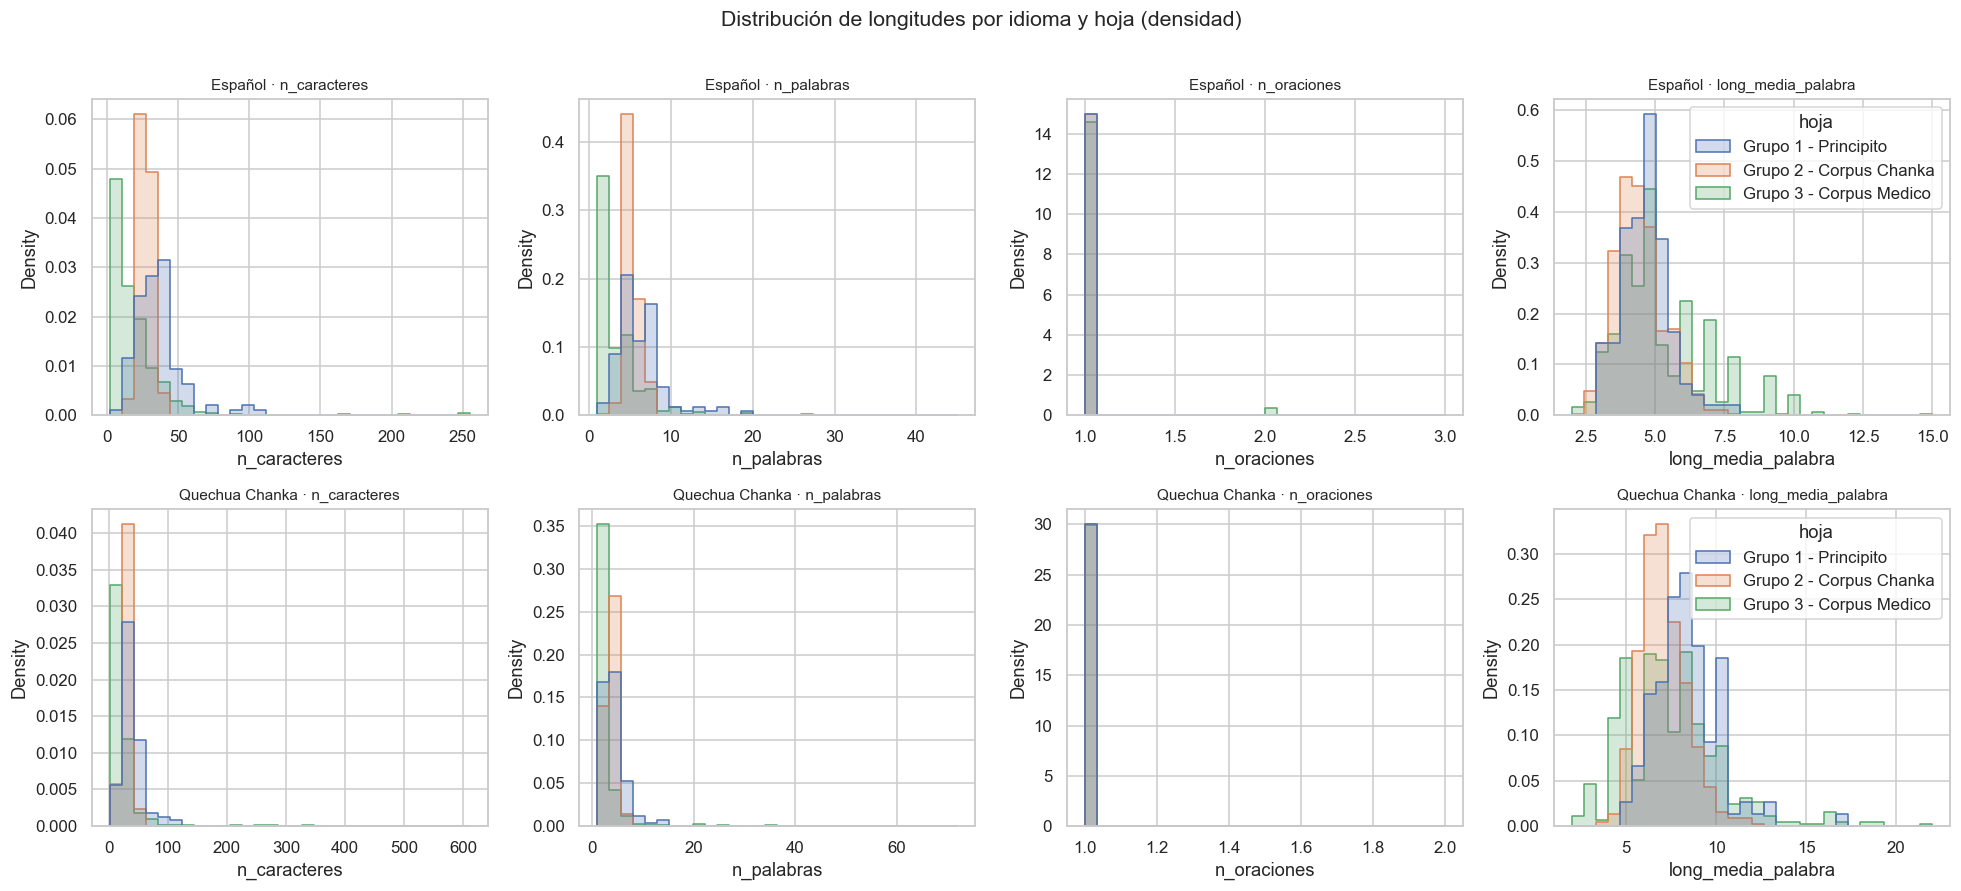

C:\Users\PC\AppData\Local\Temp\ipykernel_9896\1971158060.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([textwrap.fill(h, 18) for h in hojas])


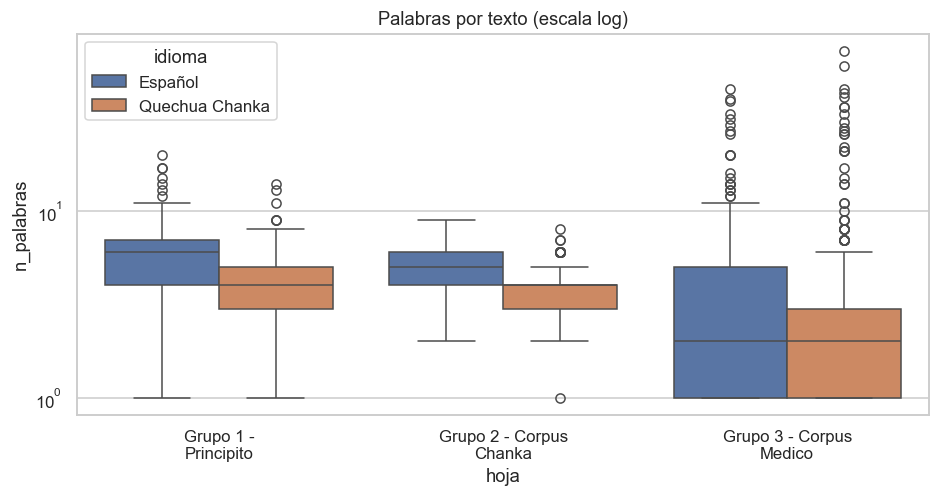

In [13]:
fig, axes = plt.subplots(len(IDIOMAS), 4, figsize=(18, 4 * len(IDIOMAS)), squeeze=False)
for r, idioma in enumerate(IDIOMAS):
    sub = corpus[corpus["idioma"] == idioma]
    for c, col in enumerate(cols_len):
        sns.histplot(data=sub, x=col, hue="hoja", hue_order=hojas, palette=PALETA_HOJAS,
                     bins=30, element="step", stat="density", common_norm=False,
                     legend=(c == 3), ax=axes[r][c])
        axes[r][c].set_title(f"{idioma} · {col}", fontsize=10)
plt.suptitle("Distribución de longitudes por idioma y hoja (densidad)", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=corpus, x="hoja", y="n_palabras", hue="idioma", order=hojas, ax=ax)
ax.set_yscale("log"); ax.set_title("Palabras por texto (escala log)")
ax.set_xticklabels([textwrap.fill(h, 18) for h in hojas])
plt.show()

In [14]:
# Textos atípicos por idioma: muy cortos y muy largos (regla del rango intercuartílico)
def lim_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

corpus["_lim_sup"] = corpus.groupby("idioma")["n_palabras"].transform(lim_iqr)
cortos = corpus[corpus["n_palabras"] < MIN_PALABRAS_CORTO]
largos = corpus[corpus["n_palabras"] > corpus["_lim_sup"]]

conteo = pd.DataFrame({"textos": corpus.groupby("idioma").size(),
                       f"muy cortos (< {MIN_PALABRAS_CORTO} palabras)": cortos.groupby("idioma").size(),
                       "muy largos (IQR)": largos.groupby("idioma").size()}).reindex(IDIOMAS).fillna(0).astype(int)
display(conteo)

print("Muy cortos:")
display(cortos[["idioma", "hoja", "fila_excel", "n_palabras", "texto"]].head(6))
print("Más largos:")
display(largos.nlargest(6, "n_palabras")[["idioma", "hoja", "fila_excel", "n_palabras", "texto"]])

,textos,muy cortos (< 2 palabras),muy largos (IQR)
idioma,,,
Español,1461,267,32
Quechua Chanka,1461,275,42


Muy cortos:


,idioma,hoja,fila_excel,n_palabras,texto
112,Español,Grupo 1 - Principito,114,1,¡Bebo!
856,Español,Grupo 3 - Corpus Medico,80,1,¿Normales?
879,Español,Grupo 3 - Corpus Medico,103,1,Respire.
886,Español,Grupo 3 - Corpus Medico,110,1,Recuéstese.
931,Español,Grupo 3 - Corpus Medico,155,1,Peínate
942,Español,Grupo 3 - Corpus Medico,166,1,Zancudo


Más largos:


,idioma,hoja,fila_excel,n_palabras,texto
2738,Quechua Chanka,Grupo 3 - Corpus Medico,503,72,ñuñu lichi sumaq alimento wawata ñuñupayana achka lichi kananpaq wawakuruspa ñuñupayana wawata l...
2731,Quechua Chanka,Grupo 3 - Corpus Medico,496,60,wawaykipaqmi kanan platocham vasochan hinaspa kucharachan sapa punchaw mikuy wawaykiwan lliw ali...
1329,Español,Grupo 3 - Corpus Medico,555,45,"Un personal de salud se pondrá en contacto con usted para monitorear su estado de salud, vía tel..."
2722,Quechua Chanka,Grupo 3 - Corpus Medico,487,45,primero makikita lava yakuwan hinaspa jabonwan segundo iskay kucharachata rakiy pipu mikuymanta ...
2725,Quechua Chanka,Grupo 3 - Corpus Medico,490,43,chay termometro sutiyoqwan cuerponchikpa rupasqanta qawasunchik iskay kutita huk punchawpi pacha...
2728,Quechua Chanka,Grupo 3 - Corpus Medico,493,41,ruwawaqmi sapayo locrochata uywapa igadunwan ruawaqmi trigola jardinera nisqanta ruwawaqmi torti...


## 4. Alineación del corpus paralelo

Si dos oraciones son traducción una de otra, su longitud suele ser proporcional. Una relación de longitudes muy fuera de lo normal
sugiere **desalineación**, traducción parcial u omisiones.

> El quechua es **aglutinante** (una palabra suele equivaler a varias del español), pero eso no impone un cociente universal de palabras. El cociente depende también del contenido y de la segmentación.
> El cociente de *caracteres* es más estable y es el que se usa para detectar candidatos a desalineación.

In [15]:
if len(IDIOMAS) >= 2:
    A, B = IDIOMAS[:2]
    print(f"A = {A}   |   B = {B}")

    pw = corpus.pivot(index=["hoja", "fila_excel"], columns="idioma", values="n_palabras")[[A, B]].dropna()
    pc = corpus.pivot(index=["hoja", "fila_excel"], columns="idioma", values="n_caracteres")[[A, B]].dropna()
    par = (pw.rename(columns={A: "pal_A", B: "pal_B"})
             .join(pc.rename(columns={A: "car_A", B: "car_B"}), how="inner").reset_index())

    par["ratio_pal"] = par["pal_B"].clip(lower=1) / par["pal_A"].clip(lower=1)
    par["ratio_car"] = par["car_B"].clip(lower=1) / par["car_A"].clip(lower=1)
    par["log2_ratio_car"] = np.log2(par["ratio_car"])

    resumen_par = par.groupby("hoja").agg(
        pares=("pal_A", "size"),
        pal_A=("pal_A", "mean"), pal_B=("pal_B", "mean"),
        ratio_pal_mediana=("ratio_pal", "median"),
        ratio_car_mediana=("ratio_car", "median"),
        ratio_car_p5=("ratio_car", lambda s: s.quantile(0.05)),
        ratio_car_p95=("ratio_car", lambda s: s.quantile(0.95)),
    )
    resumen_par["corr_palabras"]  = {h: g["pal_A"].corr(g["pal_B"]) for h, g in par.groupby("hoja")}
    resumen_par["corr_caracteres"] = {h: g["car_A"].corr(g["car_B"]) for h, g in par.groupby("hoja")}
    display(resumen_par.reindex(hojas))
else:
    print("Un solo idioma configurado: se omite el análisis de alineación.")

A = Español   |   B = Quechua Chanka


,pares,pal_A,pal_B,ratio_pal_mediana,ratio_car_mediana,ratio_car_p5,ratio_car_p95,corr_palabras,corr_caracteres
hoja,,,,,,,,,
Grupo 1 - Principito,113,6.248,4.301,0.667,1.105,0.815,1.638,0.847,0.892
Grupo 2 - Corpus Chanka,667,5.087,3.906,0.750,1.143,0.827,1.521,0.495,0.623
Grupo 3 - Corpus Medico,681,3.532,3.088,1.000,1.059,0.556,2.000,0.533,0.587


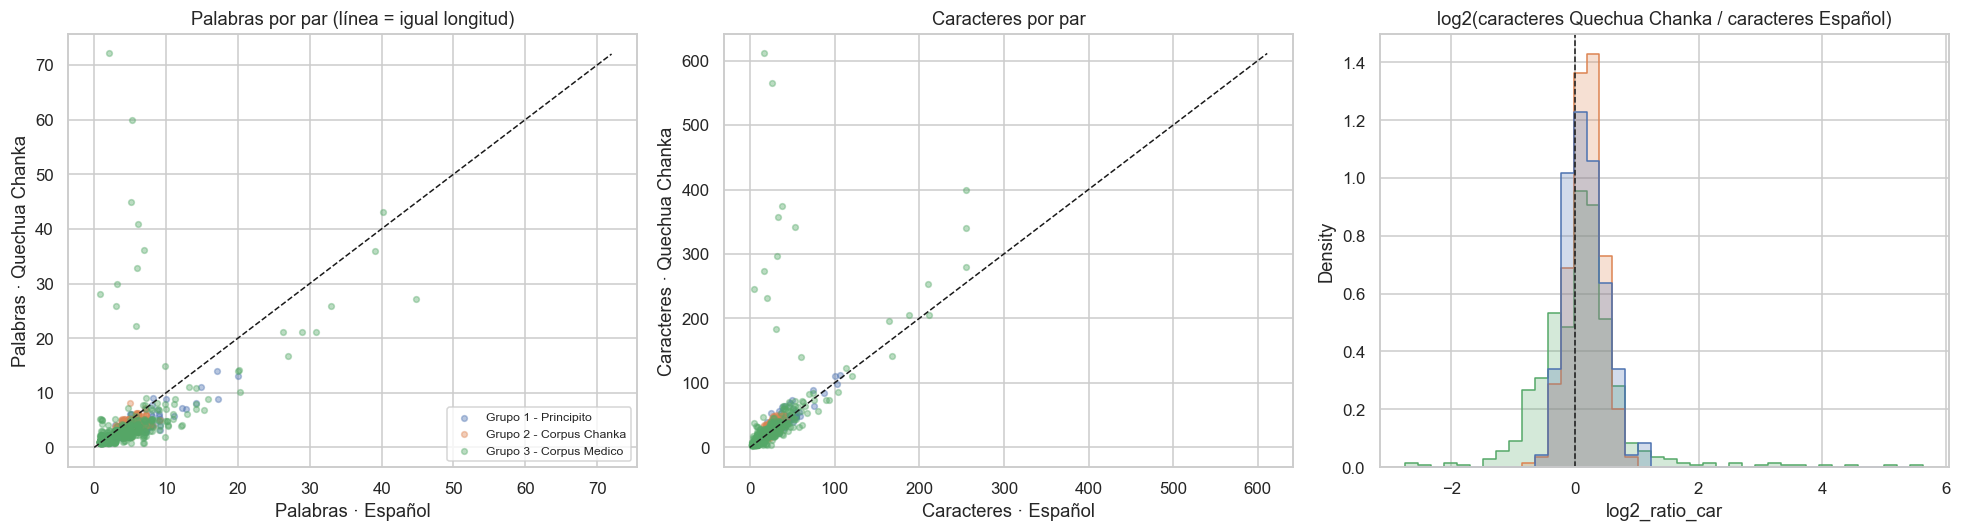

In [16]:
if len(IDIOMAS) >= 2:
    rng = np.random.default_rng(SEMILLA)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # (a) palabras A vs. B, con un pequeño jitter para ver los puntos solapados
    for h in hojas:
        g = par[par["hoja"] == h]
        axes[0].scatter(g["pal_A"] + rng.uniform(-0.25, 0.25, len(g)),
                        g["pal_B"] + rng.uniform(-0.25, 0.25, len(g)),
                        s=14, alpha=0.4, label=h, color=PALETA_HOJAS[h])
    lim = max(par["pal_A"].max(), par["pal_B"].max())
    axes[0].plot([0, lim], [0, lim], "k--", lw=1)
    axes[0].set_xlabel(f"Palabras · {A}"); axes[0].set_ylabel(f"Palabras · {B}")
    axes[0].set_title("Palabras por par (línea = igual longitud)"); axes[0].legend(fontsize=8)

    # (b) caracteres A vs. B
    for h in hojas:
        g = par[par["hoja"] == h]
        axes[1].scatter(g["car_A"], g["car_B"], s=14, alpha=0.4, color=PALETA_HOJAS[h])
    lim = max(par["car_A"].max(), par["car_B"].max())
    axes[1].plot([0, lim], [0, lim], "k--", lw=1)
    axes[1].set_xlabel(f"Caracteres · {A}"); axes[1].set_ylabel(f"Caracteres · {B}")
    axes[1].set_title("Caracteres por par")

    # (c) distribución del cociente de caracteres B/A (log2)
    sns.histplot(data=par, x="log2_ratio_car", hue="hoja", hue_order=hojas, palette=PALETA_HOJAS,
                 bins=40, element="step", stat="density", common_norm=False, legend=False, ax=axes[2])
    axes[2].axvline(0, color="k", ls="--", lw=1)
    axes[2].set_title(f"log2(caracteres {B} / caracteres {A})")
    plt.tight_layout(); plt.show()

In [17]:
if len(IDIOMAS) >= 2:
    # Candidatos a desalineación: cociente de caracteres atípico dentro de su hoja (regla del IQR)
    def marca_atipico(g):
        q1, q3 = g["log2_ratio_car"].quantile([0.25, 0.75])
        iqr = q3 - q1
        return (g["log2_ratio_car"] < q1 - 1.5 * iqr) | (g["log2_ratio_car"] > q3 + 1.5 * iqr)

    par["atipico"] = pd.concat([marca_atipico(g) for _, g in par.groupby("hoja")]).reindex(par.index)
    print(f"Pares con cociente de longitud atípico: {int(par['atipico'].sum())} de {len(par)} "
          f"({100 * par['atipico'].mean():.1f}%)")

    desv = (par["log2_ratio_car"] - par.groupby("hoja")["log2_ratio_car"].transform("median")).abs()
    candidatos = (par.assign(desviacion=desv)[par["atipico"]]
                  .sort_values("desviacion", ascending=False).head(15)
                  .merge(pares[["hoja", "fila_excel", A, B]], on=["hoja", "fila_excel"]))
    display(candidatos[["hoja", "fila_excel", "car_A", "car_B", "ratio_car", A, B]])

Pares con cociente de longitud atípico: 47 de 1461 (3.2%)


,hoja,fila_excel,car_A,car_B,ratio_car,Español,Quechua Chanka
0,Grupo 3 - Corpus Medico,491,5,246,49.200,Dieta,mikuynikiqa nada wirallawanmi kanan mikuyqa nada condementollawanmi kanan mikuyqa nada uchullawa...
1,Grupo 3 - Corpus Medico,503,17,611,35.941,Lactancia materna,ñuñu lichi sumaq alimento wawata ñuñupayana achka lichi kananpaq wawakuruspa ñuñupayana wawata l...
2,Grupo 3 - Corpus Medico,496,26,565,21.731,Es importante para tu hijo,wawaykipaqmi kanan platocham vasochan hinaspa kucharachan sapa punchaw mikuy wawaykiwan lliw ali...
3,Grupo 3 - Corpus Medico,499,17,273,16.059,Hasta los 6 meses,ñuñutam huna manam hunachu yakuchata manam hunachu qora yakukunata manam hunachu filtranteskunat...
4,Grupo 3 - Corpus Medico,492,20,232,11.600,Dieta para gestantes,mana tomanachu cafeyta mana tomanachu tita mana tomanachu cacaota hinaspa chucollatita kaykunan ...
5,Grupo 3 - Corpus Medico,493,33,357,10.818,Dieta para niños de 12 a 23 meses,ruwawaqmi sapayo locrochata uywapa igadunwan ruawaqmi trigola jardinera nisqanta ruwawaqmi torti...
6,Grupo 3 - Corpus Medico,487,38,375,9.868,Dale sus sobrecitos de micronutrientes,primero makikita lava yakuwan hinaspa jabonwan segundo iskay kucharachata rakiy pipu mikuymanta ...
7,Grupo 3 - Corpus Medico,495,32,297,9.281,Dieta para niños de 9 a 11 meses,makinchiktam labananchik manaraq mikuspa mikuyninchikta mikuruspapas labananchin wawapaq ruwawaq...
8,Grupo 3 - Corpus Medico,441,5,38,7.600,allcj,purina punchawpi kinsa chunka minututa
9,Grupo 3 - Corpus Medico,329,20,3,0.150,Enfermizo (sinónimo),eqo


## 5. Ruido textual e inventario de caracteres

Cuantifica elementos que normalmente conviene limpiar o tratar aparte antes de modelar, y lista los caracteres «no a–z» de cada idioma
(útil para detectar símbolos raros, codificaciones rotas o variantes ortográficas inconsistentes).

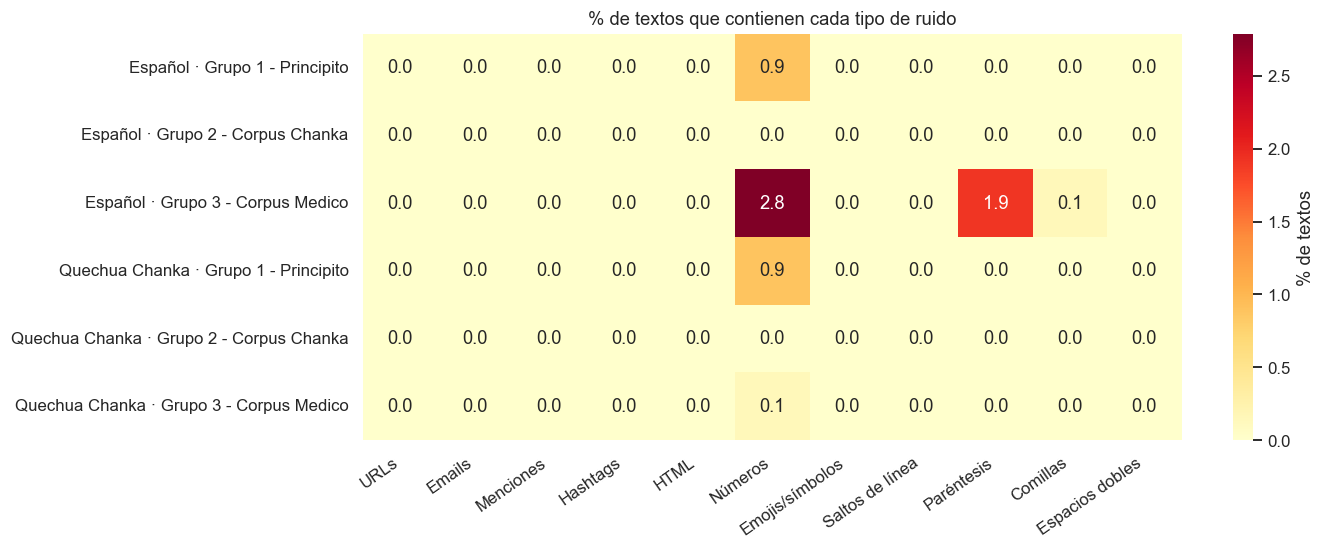

In [18]:
PATRONES_RUIDO = {
    "URLs":            r"https?://\S+|www\.\S+",
    "Emails":          r"\b[\w.+-]+@[\w-]+\.[\w.]+\b",
    "Menciones":       r"@\w+",
    "Hashtags":        r"#\w+",
    "HTML":            r"<[^>]+>|&\w+;",
    "Números":         r"\d+",
    "Emojis/símbolos": r"[\U0001F300-\U0001FAFF\u2600-\u27BF]",
    "Saltos de línea": r"[\r\n]+",
    "Paréntesis":      r"[()\[\]{}]",
    "Comillas":        r"[\"“”«»]",
    "Espacios dobles": r"\s{2,}",
}

ruido = pd.DataFrame({
    nombre: corpus["texto"].map(lambda texto: bool(re.search(patron, texto))).astype(float)
                  .groupby([corpus["idioma"], corpus["hoja"]]).mean() * 100
    for nombre, patron in PATRONES_RUIDO.items()
}).astype(float)
ruido.index = [f"{i} · {h}" for i, h in ruido.index]

plt.figure(figsize=(12, 1.5 + 0.55 * len(ruido)))
sns.heatmap(ruido, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% de textos"})
plt.title("% de textos que contienen cada tipo de ruido"); plt.ylabel("")
plt.xticks(rotation=35, ha="right"); plt.show()

In [19]:
def ratio_mayusculas(t):
    letras = [c for c in t if c.isalpha()]
    return sum(c.isupper() for c in letras) / len(letras) if letras else 0

def ratio_no_alfanum(t):
    return sum(not (c.isalnum() or c.isspace()) for c in t) / max(len(t), 1)

corpus["ratio_mayus"]    = corpus["texto"].apply(ratio_mayusculas)
corpus["ratio_simbolos"] = corpus["texto"].apply(ratio_no_alfanum)

display(corpus.groupby(["idioma", "hoja"])[["ratio_mayus", "ratio_simbolos"]].agg(["mean", "max"]))
display(corpus.nlargest(3, "ratio_mayus")[["idioma", "hoja", "ratio_mayus", "texto"]])

ratio_mayus       ratio_simbolos      
                                              mean   max           mean   max
idioma         hoja                                                          
Español        Grupo 1 - Principito          0.045 0.250          0.048 0.333
               Grupo 2 - Corpus Chanka       0.012 0.211          0.039 0.125
               Grupo 3 - Corpus Medico       0.109 0.800          0.039 0.250
Quechua Chanka Grupo 1 - Principito          0.036 0.167          0.041 0.250
               Grupo 2 - Corpus Chanka       0.039 0.143          0.035 0.125
               Grupo 3 - Corpus Medico       0.012 0.200          0.016 0.188

,idioma,hoja,ratio_mayus,texto
1458,Español,Grupo 3 - Corpus Medico,0.800,¿Tu DNI?
943,Español,Grupo 3 - Corpus Medico,0.500,Yo
959,Español,Grupo 3 - Corpus Medico,0.500,Tú


In [20]:
# Inventario de caracteres que NO son letras a-z ni espacios (por idioma)
filas = []
for idioma in IDIOMAS:
    cnt = Counter(ch for t in corpus.loc[corpus["idioma"] == idioma, "texto"] for ch in t.lower()
                  if not (ch.isascii() and (ch.isalpha() or ch.isspace())))
    for ch, n in cnt.most_common(20):
        filas.append((idioma, ch, f"U+{ord(ch):04X}", unicodedata.name(ch, "?"), n))

inventario = pd.DataFrame(filas, columns=["idioma", "caracter", "codigo", "nombre_unicode", "frecuencia"])
display(inventario)

,idioma,caracter,codigo,nombre_unicode,frecuencia
0,Español,.,U+002E,FULL STOP,789
1,Español,¿,U+00BF,INVERTED QUESTION MARK,258
2,Español,?,U+003F,QUESTION MARK,256
3,Español,ñ,U+00F1,LATIN SMALL LETTER N WITH TILDE,246
4,Español,í,U+00ED,LATIN SMALL LETTER I WITH ACUTE,141
5,Español,á,U+00E1,LATIN SMALL LETTER A WITH ACUTE,137
6,Español,ó,U+00F3,LATIN SMALL LETTER O WITH ACUTE,111
7,Español,é,U+00E9,LATIN SMALL LETTER E WITH ACUTE,111
8,Español,",",U+002C,COMMA,83
9,Español,ú,U+00FA,LATIN SMALL LETTER U WITH ACUTE,72


## 6. Normalización y tokenización

Se generan dos versiones de tokens:

- `tokens`: todas las palabras (minúsculas, sin URLs/HTML/menciones).
- `tokens_lex`: sin *stopwords* (según el idioma de cada texto) y con longitud mínima → útil para análisis de contenido.

> Para el quechua no hay lista de stopwords en NLTK. Revisa las palabras más frecuentes (sección 8) y, si lo ves útil,
> añade las funcionales a `STOPWORDS_EXTRA`.

In [21]:
import nltk
nltk.data.path.insert(0, str(Path.cwd() / 'nltk_data'))

def cargar_stopwords(lang):
    if not lang:
        return set()
    from nltk.corpus import stopwords
    try:
        return set(stopwords.words(lang))
    except LookupError:
        raise RuntimeError("Falta el recurso stopwords. Instalarlo en nltk_data antes de ejecutar; no se cambia silenciosamente el análisis.")
    try:
        return set(stopwords.words(lang))
    except Exception as e:
        raise RuntimeError(f"No se pudieron cargar las stopwords de {lang}") from e

STOP = {idioma: cargar_stopwords(lang) | {w.lower() for w in STOPWORDS_EXTRA.get(idioma, [])}
        for idioma, lang in COLS_TEXTO.items()}

for idioma, sw in STOP.items():
    print(f"{idioma}: {len(sw)} stopwords")

Español: 313 stopwords
Quechua Chanka: 0 stopwords


In [22]:
RE_URL   = re.compile(PATRONES_RUIDO["URLs"])
RE_EMAIL = re.compile(PATRONES_RUIDO["Emails"])
RE_HTML  = re.compile(PATRONES_RUIDO["HTML"])
RE_MENC  = re.compile(PATRONES_RUIDO["Menciones"])

def limpiar(t):
    t = t.lower()
    for rx in (RE_URL, RE_EMAIL, RE_HTML, RE_MENC):
        t = rx.sub(" ", t)
    return t

# Vista de selección: conserva negación, personas, números y apóstrofos.
RE_SELECCION = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)*|\d+(?:[.,]\d+)*", re.UNICODE)
def tokens_seleccion(texto):
    return RE_SELECCION.findall(normalizar_unicode(str(texto)).casefold())
corpus['tokens_seleccion'] = corpus.texto.map(tokens_seleccion)
corpus["texto_limpio"] = corpus["texto"].apply(limpiar)
corpus["tokens"]       = corpus["texto_limpio"].apply(tokenizar_simple)
corpus["tokens_lex"]   = [[t for t in ts if t not in STOP[idioma] and len(t) >= MIN_LETRAS_TOKEN]
                          for ts, idioma in zip(corpus["tokens"], corpus["idioma"])]

corpus[["idioma", "hoja", "texto", "tokens_lex"]].sample(6, random_state=SEMILLA)

,idioma,hoja,texto,tokens_lex
423,Español,Grupo 2 - Corpus Chanka,él no espera en silencio.,"[espera, silencio]"
1860,Quechua Chanka,Grupo 2 - Corpus Chanka,Qam takita uyarinki.,"[qam, takita, uyarinki]"
1337,Español,Grupo 3 - Corpus Medico,¿Comes bien?,"[comes, bien]"
506,Español,Grupo 2 - Corpus Chanka,ella limpia la casa.,"[limpia, casa]"
2012,Quechua Chanka,Grupo 2 - Corpus Chanka,Warmi warmakuna ruwanata chiqninku.,"[warmi, warmakuna, ruwanata, chiqninku]"
211,Español,Grupo 2 - Corpus Chanka,Mi abuela prepara las medicinas.,"[abuela, prepara, medicinas]"


## 7. Vocabulario

- **Tokens (N)**: total de palabras. **Tipos (V)**: palabras distintas.
- **TTR** = V / N (riqueza léxica; baja al crecer el corpus, así que compara con cautela hojas de distinto tamaño).
- **Hapax**: palabras que aparecen una sola vez (cola larga, errores ortográficos o términos muy específicos).

> En lenguas aglutinantes como el quechua es normal ver más tipos distintos y más hapax que en español, porque una misma raíz
> aparece con muchas combinaciones de sufijos.

In [23]:
def metricas_vocab(listas_tokens):
    c = Counter(t for ts in listas_tokens for t in ts)
    N, V = sum(c.values()), len(c)
    hapax = sum(1 for v in c.values() if v == 1)
    return {"textos": len(listas_tokens), "tokens (N)": N, "tipos (V)": V,
            "TTR": V / N if N else 0.0, "hapax": hapax,
            "% hapax sobre V": 100 * hapax / V if V else 0.0,
            "tokens/texto": N / len(listas_tokens) if listas_tokens else 0.0}

filas = {}
for idioma in IDIOMAS:
    sub_i = corpus[corpus["idioma"] == idioma]
    for hoja in hojas:
        filas[(idioma, hoja)] = metricas_vocab(sub_i.loc[sub_i["hoja"] == hoja, "tokens_lex"].tolist())
    filas[(idioma, "TOTAL")] = metricas_vocab(sub_i["tokens_lex"].tolist())

tabla_vocab = pd.DataFrame.from_dict(filas, orient="index")
tabla_vocab.index = pd.MultiIndex.from_tuples(tabla_vocab.index, names=["idioma", "hoja"])
display(tabla_vocab)

textos  tokens (N)  tipos (V)   TTR  \
idioma         hoja                                                           
Español        Grupo 1 - Principito        113         360        266 0.739   
               Grupo 2 - Corpus Chanka     667        1664        480 0.288   
               Grupo 3 - Corpus Medico     681        1440        837 0.581   
               TOTAL                      1461        3464       1419 0.410   
Quechua Chanka Grupo 1 - Principito        113         486        357 0.735   
               Grupo 2 - Corpus Chanka     667        2605        663 0.255   
               Grupo 3 - Corpus Medico     681        2096       1406 0.671   
               TOTAL                      1461        5187       2275 0.439   

                                        hapax  % hapax sobre V  tokens/texto  
idioma         hoja                                                           
Español        Grupo 1 - Principito       210           78.947         3.186  
               Grupo 2 - Corpus Chanka    237           49.375         2.495  
               Grupo 3 - Corpus Medico    609           72.760         2.115  
               TOTAL                      899           63.354         2.371  
Quechua Chanka Grupo 1 - Principito       297           83.193         4.301  
               Grupo 2 - Corpus Chanka    365           55.053         3.906  
               Grupo 3 - Corpus Medico   1146           81.508         3.078  
               TOTAL                     1673           73.538         3.550

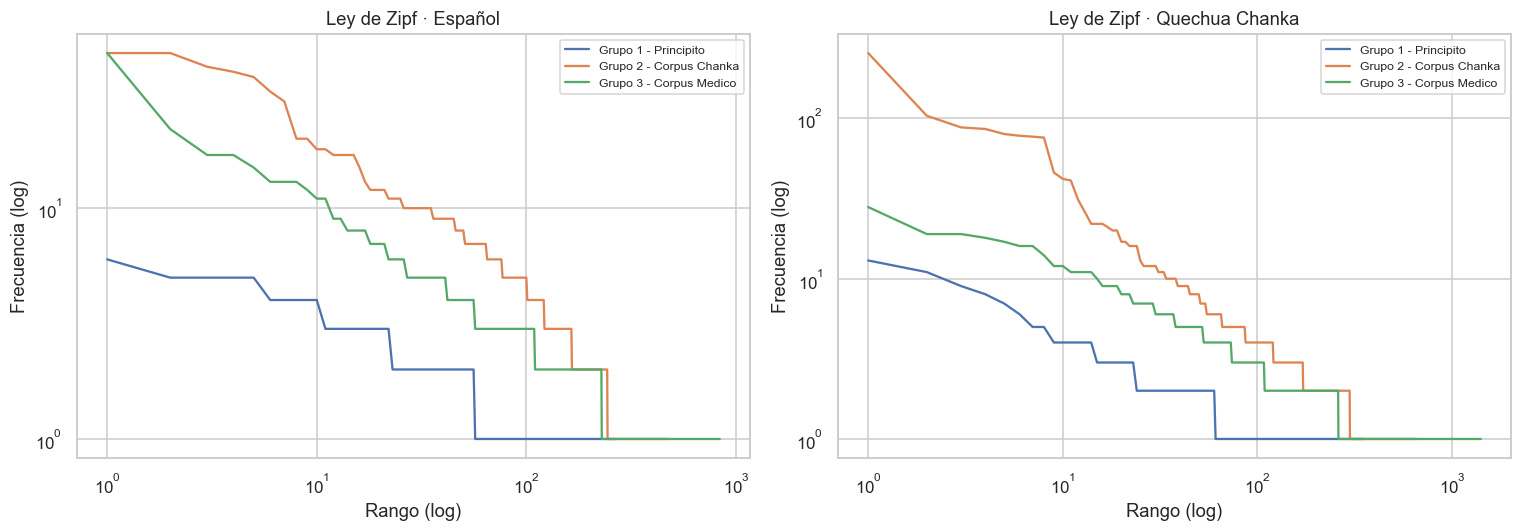

In [24]:
# Ley de Zipf: frecuencia vs. rango en escala log-log (un corpus "natural" se acerca a una recta)
fig, axes = plt.subplots(1, len(IDIOMAS), figsize=(7 * len(IDIOMAS), 5), squeeze=False)
for ax, idioma in zip(axes[0], IDIOMAS):
    for hoja in hojas:
        g = corpus[(corpus["idioma"] == idioma) & (corpus["hoja"] == hoja)]
        frec = np.array(sorted(Counter(t for ts in g["tokens_lex"] for t in ts).values(), reverse=True))
        if len(frec):
            ax.loglog(np.arange(1, len(frec) + 1), frec, label=hoja, color=PALETA_HOJAS[hoja])
    ax.set_xlabel("Rango (log)"); ax.set_ylabel("Frecuencia (log)")
    ax.set_title(f"Ley de Zipf · {idioma}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

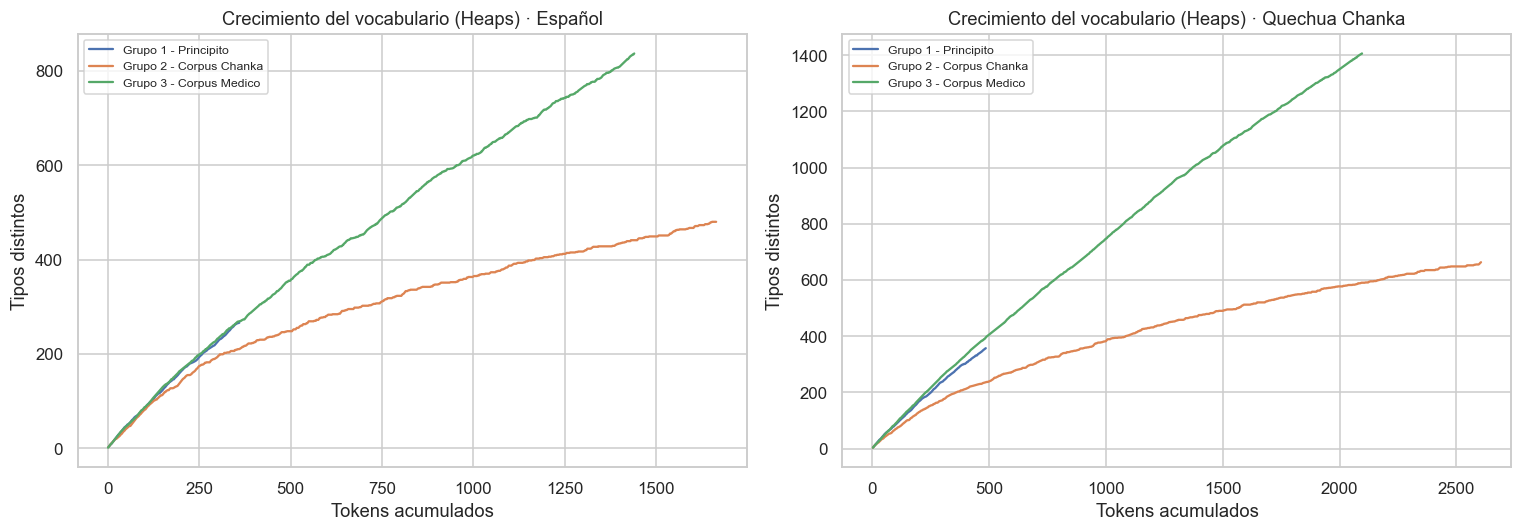

In [25]:
# Curva de crecimiento del vocabulario (ley de Heaps): ¿sigue apareciendo vocabulario nuevo?
rng = np.random.default_rng(SEMILLA)
fig, axes = plt.subplots(1, len(IDIOMAS), figsize=(7 * len(IDIOMAS), 5), squeeze=False)
for ax, idioma in zip(axes[0], IDIOMAS):
    for hoja in hojas:
        docs = corpus.loc[(corpus["idioma"] == idioma) & (corpus["hoja"] == hoja), "tokens_lex"].tolist()
        if not docs:
            continue
        rng.shuffle(docs)
        vistos, tipos, acum_n, n_tok = set(), [], [], 0
        for ts in docs:
            vistos.update(ts); n_tok += len(ts)
            tipos.append(len(vistos)); acum_n.append(n_tok)
        ax.plot(acum_n, tipos, label=hoja, color=PALETA_HOJAS[hoja])
    ax.set_xlabel("Tokens acumulados"); ax.set_ylabel("Tipos distintos")
    ax.set_title(f"Crecimiento del vocabulario (Heaps) · {idioma}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Palabras más frecuentes

Una cuadrícula: **filas = idioma**, **columnas = hoja**. Los gráficos de hojas sin palabras se rellenan con un aviso en lugar de fallar.

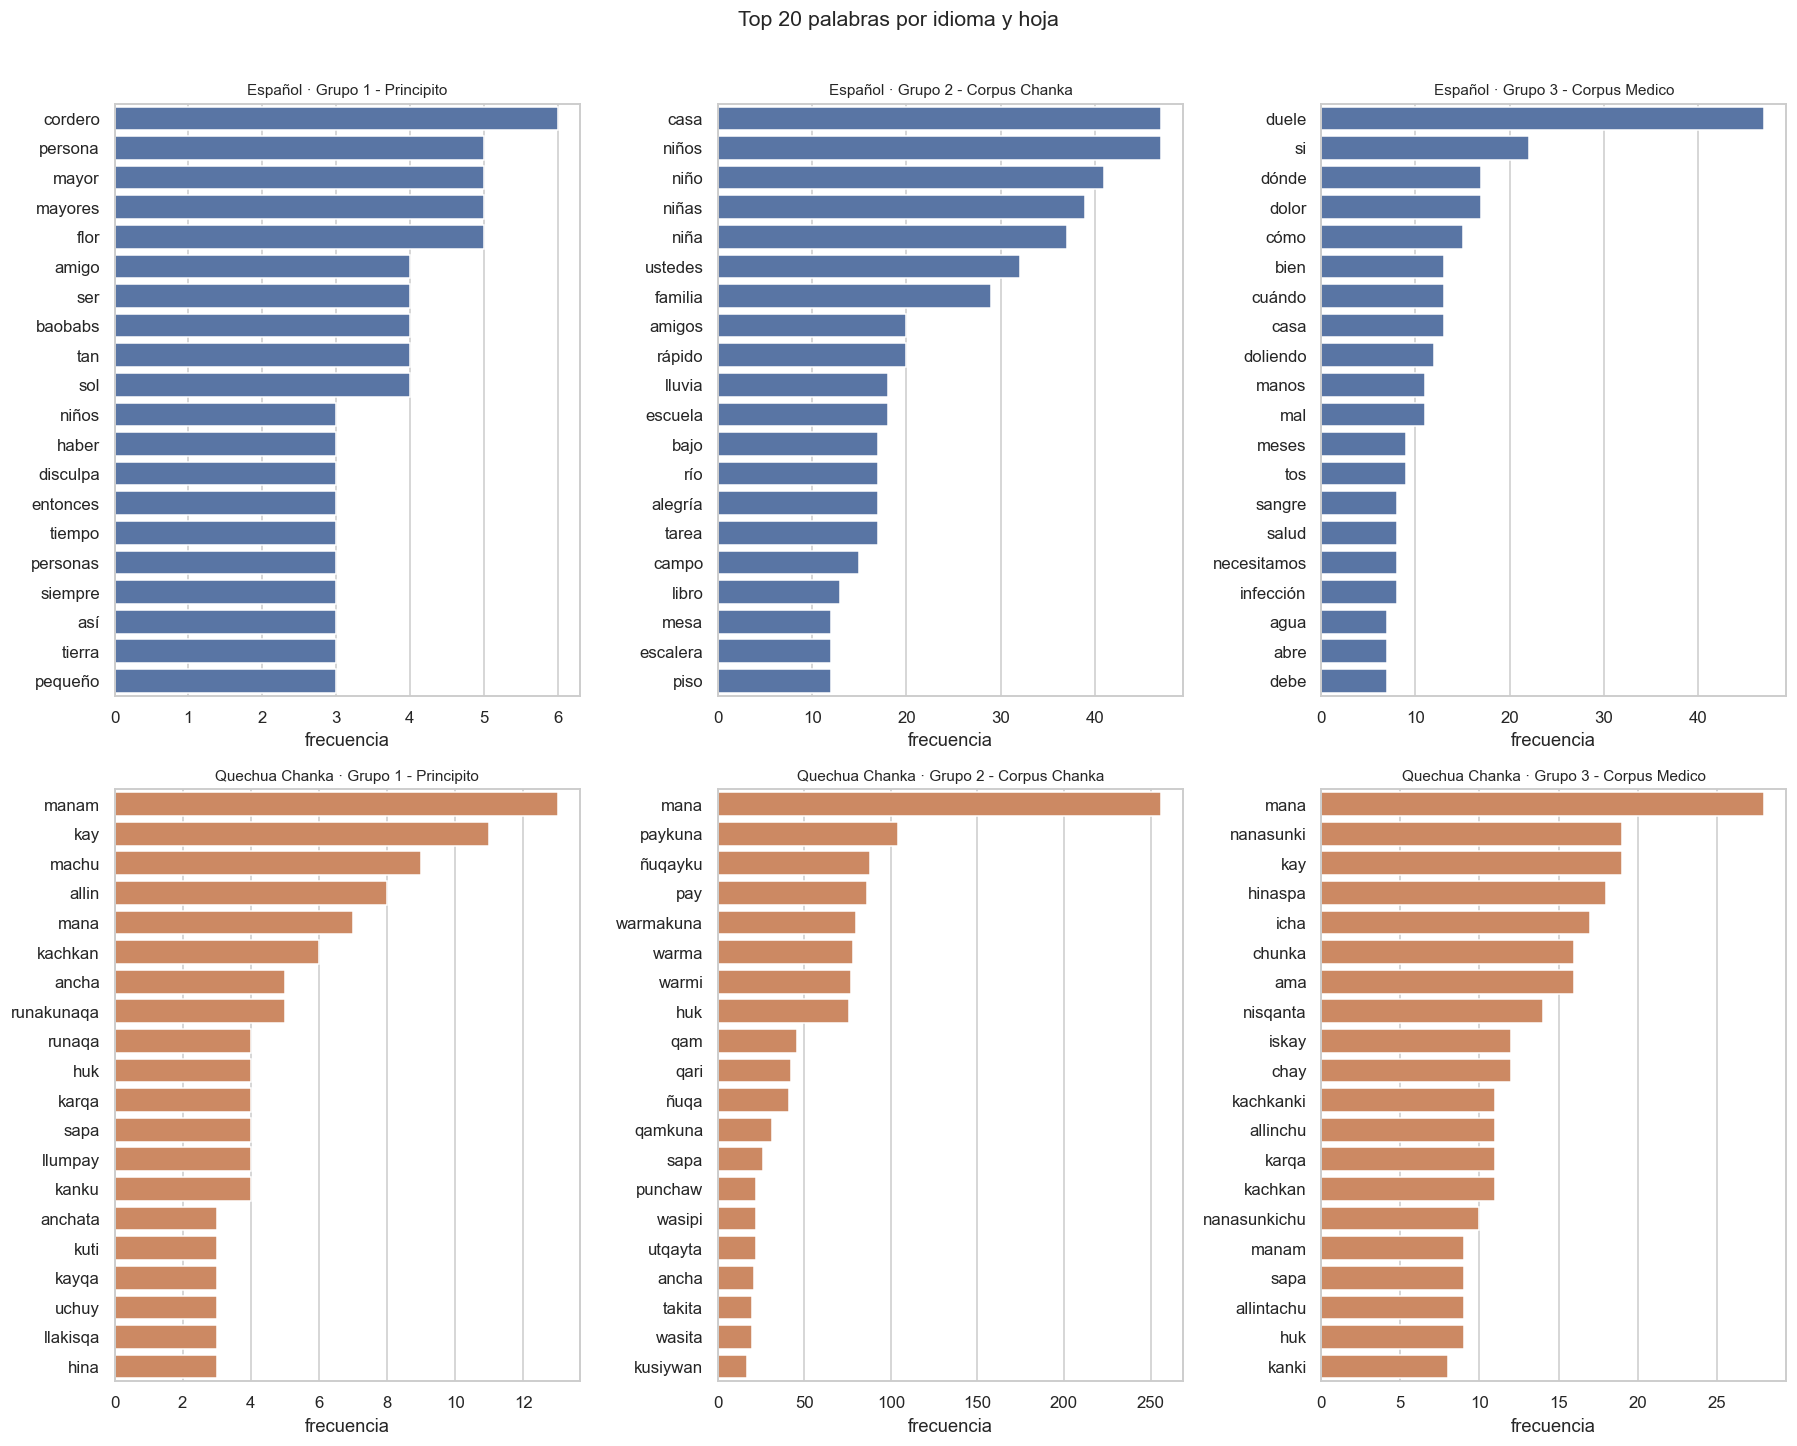

In [26]:
def sin_datos(ax):
    ax.text(0.5, 0.5, "Sin palabras", ha="center", va="center", transform=ax.transAxes, color="gray")
    ax.axis("off")

def grilla(dibujar, titulo, ancho=5.5, alto=5.5):
    # Cuadrícula idioma (filas) x hoja (columnas); `dibujar(ax, sub, color)` pinta cada celda
    fig, axes = plt.subplots(len(IDIOMAS), len(hojas), figsize=(ancho * len(hojas), alto * len(IDIOMAS)),
                             squeeze=False)
    for r, idioma in enumerate(IDIOMAS):
        for c, hoja in enumerate(hojas):
            sub = corpus[(corpus["idioma"] == idioma) & (corpus["hoja"] == hoja)]
            ax = axes[r][c]
            dibujar(ax, sub, sns.color_palette()[r % 10])
            ax.set_title(f"{idioma} · {textwrap.shorten(hoja, 34)}", fontsize=10)
    fig.suptitle(titulo, y=1.01, fontsize=14)
    plt.tight_layout(); plt.show()

def dibujar_top(ax, sub, color):
    cnt = Counter(t for ts in sub["tokens_lex"] for t in ts)
    if not cnt:
        return sin_datos(ax)
    top = pd.DataFrame(cnt.most_common(TOP_N), columns=["palabra", "frecuencia"])
    sns.barplot(data=top, y="palabra", x="frecuencia", ax=ax, color=color)
    ax.set_ylabel("")

grilla(dibujar_top, f"Top {TOP_N} palabras por idioma y hoja", alto=6.5)

In [27]:
# Nube de palabras (opcional; requiere `pip install wordcloud`)
try:
    from wordcloud import WordCloud

    def dibujar_nube(ax, sub, color):
        cnt = Counter(t for ts in sub["tokens_lex"] for t in ts)
        if not cnt:
            return sin_datos(ax)
        wc = WordCloud(width=700, height=450, background_color="white",
                       random_state=SEMILLA).generate_from_frequencies(cnt)
        ax.imshow(wc, interpolation="bilinear"); ax.axis("off")

    grilla(dibujar_nube, "Nubes de palabras", ancho=6, alto=3.8)
except ImportError:
    print("wordcloud no está instalado: se omite la nube de palabras.")

wordcloud no está instalado: se omite la nube de palabras.


## 9. N-gramas contiguos

Se calculan sobre `tokens_seleccion`, conservando palabras funcionales, negación y números.
Son contiguos en la secuencia tokenizada de cada fila; la puntuación no se representa y una
fila con varias oraciones todavía puede crear cruces de frontera. No se interpretan como
patrones sintácticos ni se usa su frecuencia como garantía de naturalidad.


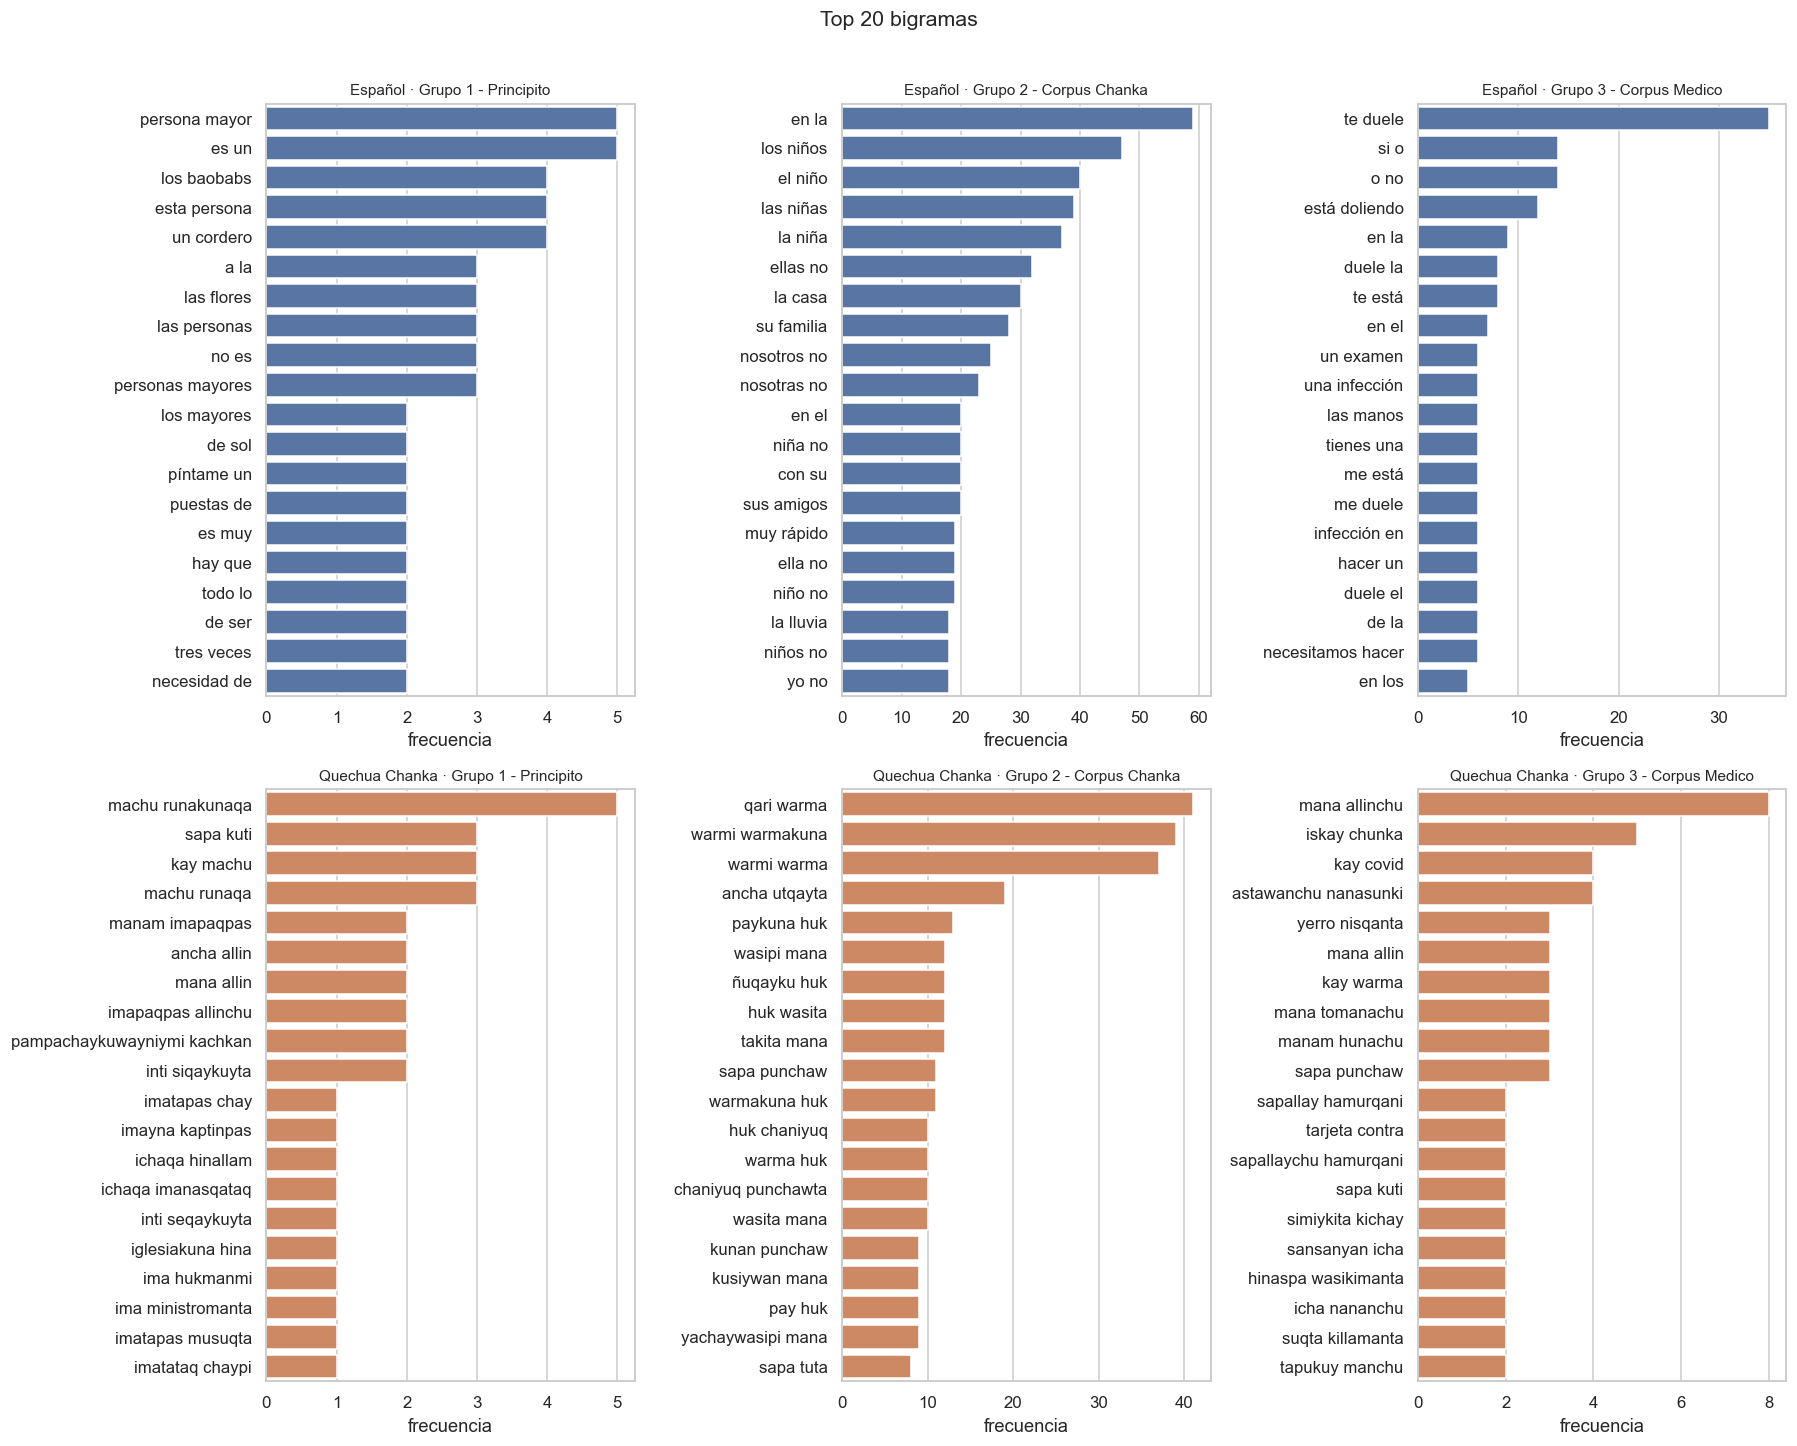

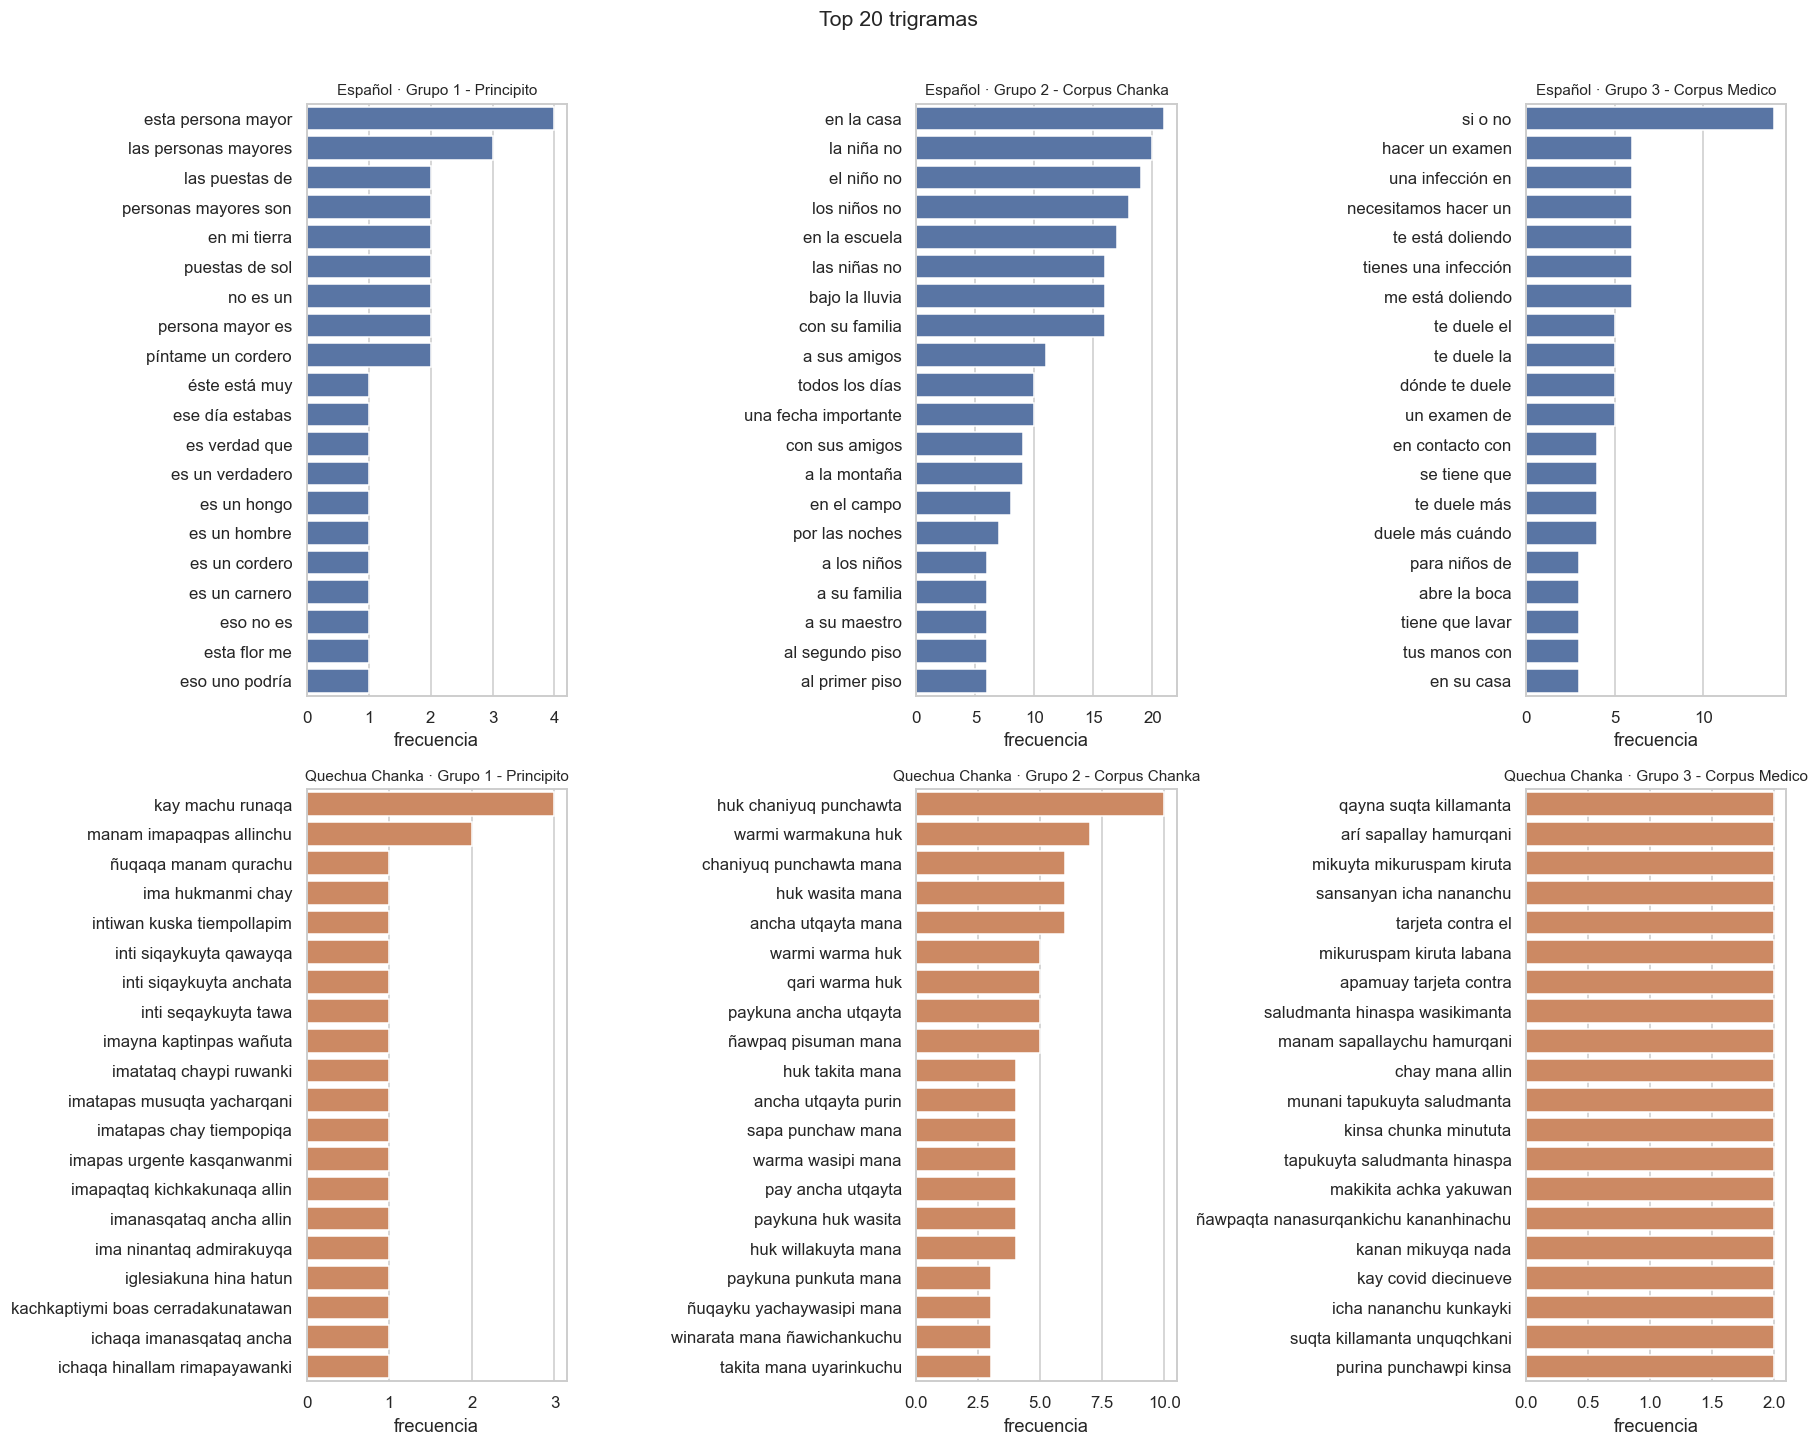

In [28]:
def top_ngramas(listas_tokens, n=2, k=TOP_N):
    textos = [" ".join(ts) for ts in listas_tokens if ts]
    cv = CountVectorizer(ngram_range=(n, n), tokenizer=str.split, token_pattern=None, lowercase=False)
    X = cv.fit_transform(textos)                       # lanza ValueError si no hay vocabulario
    frec = np.asarray(X.sum(axis=0)).ravel()
    idx = frec.argsort()[::-1][:k]
    return pd.DataFrame({"ngrama": cv.get_feature_names_out()[idx], "frecuencia": frec[idx]})

def dibujar_ngramas(n):
    def dibujar(ax, sub, color):
        try:
            top = top_ngramas(sub["tokens_seleccion"].tolist(), n=n)
        except ValueError:
            return sin_datos(ax)
        sns.barplot(data=top, y="ngrama", x="frecuencia", ax=ax, color=color)
        ax.set_ylabel("")
    return dibujar

grilla(dibujar_ngramas(2), f"Top {TOP_N} bigramas", alto=6.5)
grilla(dibujar_ngramas(3), f"Top {TOP_N} trigramas", alto=6.5)

## 10. Comparación entre hojas y entre idiomas

¿Los subcorpus tratan de lo mismo o son dominios distintos? Por **idioma**:

1. **Solapamiento de vocabulario** (Jaccard) entre hojas.
2. **Términos distintivos** de cada hoja (TF-IDF tratando cada hoja como un documento).
3. **Similitud coseno** entre los centroides TF-IDF de cada hoja.

Y entre **idiomas**: qué palabras del quechua coinciden con palabras del español (préstamos, nombres propios, mezcla de códigos u homógrafos).

Español — vocabulario exclusivo de cada hoja:
   Grupo 1 - Principito: 199 tipos exclusivos (74.8% de su vocabulario)
   Grupo 2 - Corpus Chanka: 373 tipos exclusivos (77.7% de su vocabulario)
   Grupo 3 - Corpus Medico: 704 tipos exclusivos (84.1% de su vocabulario)
Quechua Chanka — vocabulario exclusivo de cada hoja:
   Grupo 1 - Principito: 282 tipos exclusivos (79.0% de su vocabulario)
   Grupo 2 - Corpus Chanka: 577 tipos exclusivos (87.0% de su vocabulario)
   Grupo 3 - Corpus Medico: 1,291 tipos exclusivos (91.8% de su vocabulario)


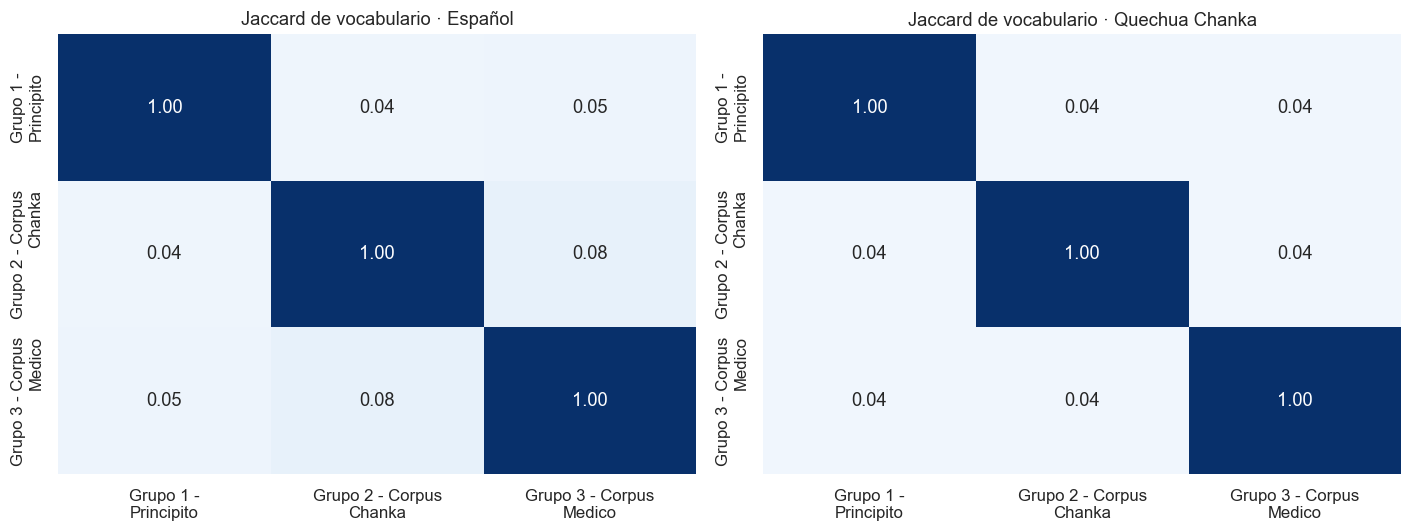

In [29]:
def etq(h):
    return textwrap.fill(h, 16)

# 10.1 Jaccard entre vocabularios de las hojas (por idioma)
fig, axes = plt.subplots(1, len(IDIOMAS), figsize=(6.5 * len(IDIOMAS), 5), squeeze=False)
for ax, idioma in zip(axes[0], IDIOMAS):
    vocabs = {h: set(t for ts in corpus.loc[(corpus["idioma"] == idioma) & (corpus["hoja"] == h), "tokens_lex"]
                     for t in ts) for h in hojas}
    jac = pd.DataFrame(1.0, index=hojas, columns=hojas)
    for a, b in combinations(hojas, 2):
        union = len(vocabs[a] | vocabs[b])
        jac.loc[a, b] = jac.loc[b, a] = len(vocabs[a] & vocabs[b]) / union if union else 0.0
    sns.heatmap(jac.rename(index=etq, columns=etq), annot=True, fmt=".2f", cmap="Blues",
                vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"Jaccard de vocabulario · {idioma}")

    print(f"{idioma} — vocabulario exclusivo de cada hoja:")
    for h in hojas:
        otros = set().union(*[v for k, v in vocabs.items() if k != h]) if len(hojas) > 1 else set()
        excl = vocabs[h] - otros
        pct = 100 * len(excl) / len(vocabs[h]) if vocabs[h] else 0
        print(f"   {h}: {len(excl):,} tipos exclusivos ({pct:.1f}% de su vocabulario)")
plt.tight_layout(); plt.show()

In [30]:
# 10.2 Términos distintivos por hoja (cada hoja = un documento grande), por idioma
distintivos = {}
for idioma in IDIOMAS:
    docs = {h: " ".join(t for ts in corpus.loc[(corpus["idioma"] == idioma) & (corpus["hoja"] == h), "tokens_lex"]
                        for t in ts) for h in hojas}
    tf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, sublinear_tf=True)
    try:
        M = tf.fit_transform(list(docs.values()))
    except ValueError:
        print(f"{idioma}: sin vocabulario suficiente.")
        continue
    terminos = tf.get_feature_names_out()
    for i, h in enumerate(docs):
        distintivos[(idioma, h)] = pd.Series(terminos[M[i].toarray().ravel().argsort()[::-1][:15]])

display(pd.DataFrame(distintivos))

Español                                                  \
   Grupo 1 - Principito Grupo 2 - Corpus Chanka Grupo 3 - Corpus Medico   
0               cordero                   niñas                   duele   
1               mayores                    niña                   dolor   
2               baobabs                  lluvia                  cuándo   
3                   tan                 escuela                doliendo   
4              entonces                     río                     mal   
5               pequeño                   tarea                   meses   
6              disculpa                   campo                     tos   
7                flores                    casa                      si   
8               persona                    piso                  sangre   
9                  flor                  música             necesitamos   
10                mayor                escalera               infección   
11                  ser                    mesa                   salud   
12                  sol                historia                  examen   
13                amigo                silencio                    debe   
14              colores               recuerdan                    cómo   

         Quechua Chanka                                                  
   Grupo 1 - Principito Grupo 2 - Corpus Chanka Grupo 3 - Corpus Medico  
0                 manam                 ñuqayku               nanasunki  
1            runakunaqa                     pay                    icha  
2                 machu               warmakuna                nisqanta  
3                 kanku                 paykuna               kachkanki  
4                runaqa                   warmi            nanasunkichu  
5                 kayqa                  wasita              allintachu  
6                   kay                  takita                 hinaspa  
7                 ancha                    mana                  mikuna  
8                 allin            yachaywasipi                   kanan  
9               llumpay                kusiywan                examenta  
10                karqa               ayllunwan                  chunka  
11                 mana                  parapi                   mikuy  
12            kaptinpas                 maytuta                    kara  
13               kanman                     qam               nanachkan  
14             churayki                    qari                nananchu

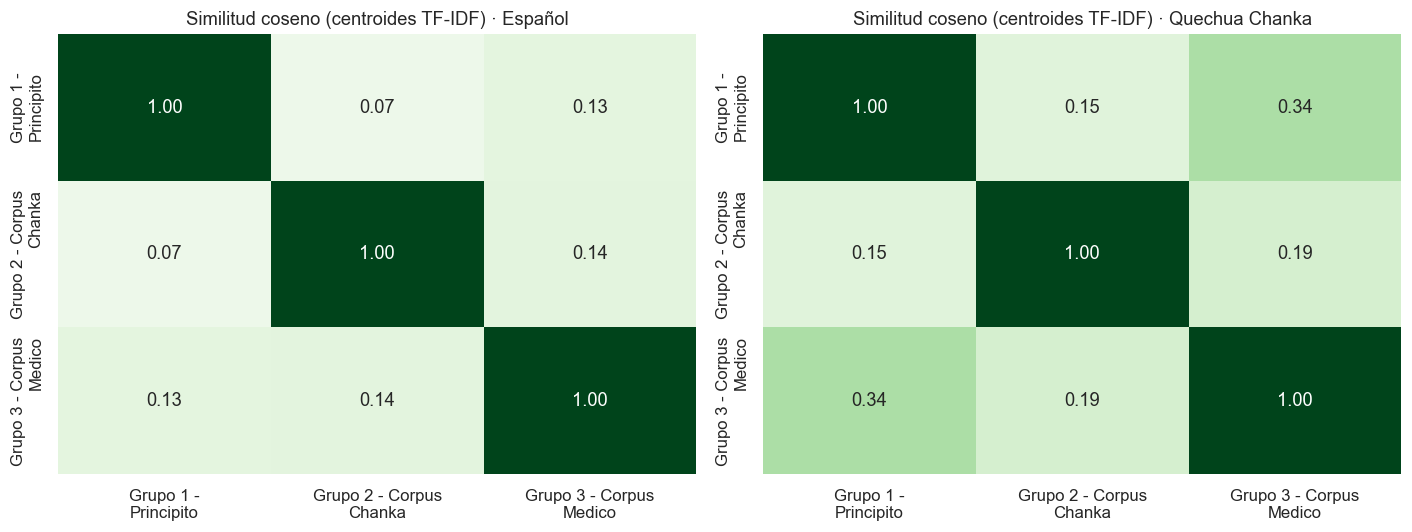

In [31]:
# 10.3 Similitud coseno entre centroides TF-IDF por hoja (y matrices TF-IDF reutilizables para la sección 11)
tfidf_idioma = {}
fig, axes = plt.subplots(1, len(IDIOMAS), figsize=(6.5 * len(IDIOMAS), 5), squeeze=False)
for ax, idioma in zip(axes[0], IDIOMAS):
    sub = corpus[corpus["idioma"] == idioma].reset_index(drop=True)
    tf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, sublinear_tf=True,
                         min_df=2 if len(sub) > 50 else 1, max_features=20000)
    try:
        X = tf.fit_transform(sub["tokens_lex"].apply(" ".join))
    except ValueError:
        ax.set_title(f"{idioma}: sin vocabulario"); ax.axis("off")
        continue
    tfidf_idioma[idioma] = (sub, X)

    cent = np.vstack([np.asarray(X[(sub["hoja"] == h).values].mean(axis=0)) for h in hojas])
    sim = pd.DataFrame(cosine_similarity(np.nan_to_num(cent)), index=hojas, columns=hojas)
    sns.heatmap(sim.rename(index=etq, columns=etq), annot=True, fmt=".2f", cmap="Greens",
                vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"Similitud coseno (centroides TF-IDF) · {idioma}")
plt.tight_layout(); plt.show()

In [32]:
# 10.4 Léxico compartido entre idiomas (préstamos, nombres propios, mezcla de códigos, homógrafos)
if len(IDIOMAS) >= 2:
    A, B = IDIOMAS[:2]
    cnt_A = Counter(t for ts in corpus.loc[corpus["idioma"] == A, "tokens_lex"] for t in ts)
    cnt_B = Counter(t for ts in corpus.loc[corpus["idioma"] == B, "tokens_lex"] for t in ts)
    compartidos = set(cnt_A) & set(cnt_B)

    print(f"Tipos en {A}: {len(cnt_A):,}  |  tipos en {B}: {len(cnt_B):,}")
    print(f"Tipos presentes en ambos idiomas: {len(compartidos):,}")
    print(f"   = {100 * len(compartidos) / max(len(cnt_B), 1):.1f}% del vocabulario de {B}")
    print(f"   = {100 * sum(cnt_B[t] for t in compartidos) / max(sum(cnt_B.values()), 1):.1f}% de los tokens de {B}")

    tabla = pd.DataFrame({"palabra": list(compartidos),
                          f"frec {A}": [cnt_A[t] for t in compartidos],
                          f"frec {B}": [cnt_B[t] for t in compartidos]})
    display(tabla.sort_values(f"frec {B}", ascending=False).head(25).reset_index(drop=True))
else:
    print("Un solo idioma configurado: se omite la comparación entre idiomas.")

Tipos en Español: 1,419  |  tipos en Quechua Chanka: 2,275
Tipos presentes en ambos idiomas: 53
   = 2.3% del vocabulario de Quechua Chanka
   = 1.7% de los tokens de Quechua Chanka


,palabra,frec Español,frec Quechua Chanka
0,ama,5,19
1,covid,5,4
2,yawar,1,3
3,pastilla,1,3
4,tableta,1,2
5,punta,1,2
6,acido,1,2
7,alimento,2,2
8,tarjeta,3,2
9,segundo,6,2


## 11. Proyección 2D del corpus

TF-IDF + SVD truncado, por idioma. Si las hojas forman nubes separadas, tienen vocabularios/temas diferenciables;
si se mezclan, la proyección no permite separarlas. El solapamiento en dos dimensiones no demuestra homogeneidad; consultar la varianza explicada.

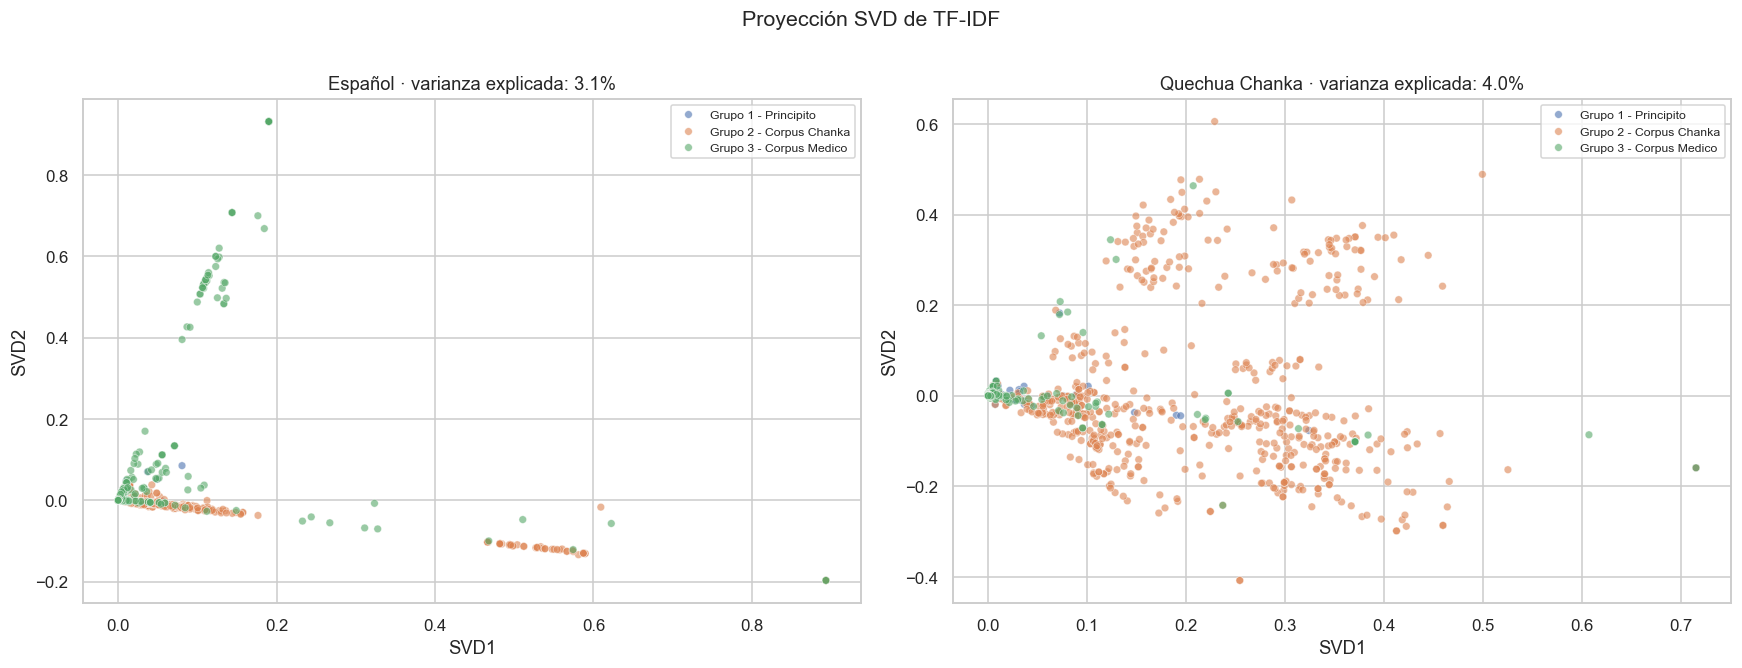

In [33]:
if not tfidf_idioma:
    print("No hay matrices TF-IDF disponibles.")
else:
    fig, axes = plt.subplots(1, len(tfidf_idioma), figsize=(8 * len(tfidf_idioma), 6), squeeze=False)
    for ax, (idioma, (sub, X)) in zip(axes[0], tfidf_idioma.items()):
        pos = np.arange(len(sub))
        if len(pos) > MAX_DOCS_PROYECCION:
            pos = np.random.default_rng(SEMILLA).choice(pos, MAX_DOCS_PROYECCION, replace=False)

        svd = TruncatedSVD(n_components=2, random_state=SEMILLA)
        Z = svd.fit_transform(X[pos])
        plot_df = pd.DataFrame({"SVD1": Z[:, 0], "SVD2": Z[:, 1], "hoja": sub["hoja"].values[pos]})
        sns.scatterplot(data=plot_df, x="SVD1", y="SVD2", hue="hoja", hue_order=hojas,
                        palette=PALETA_HOJAS, alpha=0.6, s=25, ax=ax)
        ax.set_title(f"{idioma} · varianza explicada: {svd.explained_variance_ratio_.sum():.1%}")
        ax.legend(fontsize=8)
    plt.suptitle("Proyección SVD de TF-IDF", y=1.01, fontsize=14)
    plt.tight_layout(); plt.show()

## 12. Distribución de etiquetas

Solo se ejecuta si definiste `COL_ETIQUETA`. Revisa el **desbalance de clases** y si cada hoja tiene una distribución distinta.

In [34]:
if "etiqueta" in pares.columns:
    print(pares["etiqueta"].value_counts(dropna=False))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.countplot(data=pares, y="etiqueta", hue="hoja", hue_order=hojas, palette=PALETA_HOJAS, ax=axes[0],
                  order=pares["etiqueta"].value_counts().index)
    axes[0].set_title("Pares por etiqueta y hoja")

    prop = pd.crosstab(pares["hoja"], pares["etiqueta"], normalize="index") * 100
    sns.heatmap(prop, annot=True, fmt=".1f", cmap="PuBu", ax=axes[1], cbar_kws={"label": "% dentro de la hoja"})
    axes[1].set_title("Composición de etiquetas por hoja")
    plt.tight_layout(); plt.show()

    display(corpus.groupby(["idioma", "etiqueta"])["n_palabras"].describe())
else:
    print("No se definió COL_ETIQUETA: se omite esta sección.")

No se definió COL_ETIQUETA: se omite esta sección.


## 13. Análisis lingüístico opcional (spaCy)

Activa `USAR_SPACY = True`. Solo se analizan los idiomas que tengan modelo en `MODELOS_SPACY` (no existe modelo de quechua).
Para español:

```bash
pip install spacy
python -m spacy download es_core_news_sm
```

In [35]:
if USAR_SPACY:
    import spacy

    for idioma, modelo in MODELOS_SPACY.items():
        if idioma not in IDIOMAS:
            continue
        nlp = spacy.load(modelo, disable=["lemmatizer"])
        sub = corpus[corpus["idioma"] == idioma]
        muestra = pd.concat([g.sample(min(len(g), 300), random_state=SEMILLA) for _, g in sub.groupby("hoja")])

        pos_rows, ent_rows = [], []
        for hoja, doc in zip(muestra["hoja"], nlp.pipe(muestra["texto"].str.slice(0, 2000), batch_size=64)):
            pos_rows += [(hoja, t.pos_) for t in doc if t.is_alpha]
            ent_rows += [(hoja, e.label_, e.text) for e in doc.ents]

        pos = pd.DataFrame(pos_rows, columns=["hoja", "pos"])
        pos_dist = pd.crosstab(pos["pos"], pos["hoja"], normalize="columns") * 100
        pos_dist.plot(kind="bar", figsize=(12, 4), title=f"{idioma}: categorías gramaticales (% por hoja)")
        plt.show()

        ents = pd.DataFrame(ent_rows, columns=["hoja", "tipo", "entidad"])
        if len(ents):
            print(f"{idioma}: entidades por tipo y hoja")
            display(ents.groupby(["tipo", "hoja"]).size().unstack("hoja").fillna(0).astype(int))
            display(ents["entidad"].value_counts().head(15).to_frame("frecuencia"))
        else:
            print(f"{idioma}: no se detectaron entidades en la muestra.")
else:
    print("USAR_SPACY = False: se omite esta sección.")

USAR_SPACY = False: se omite esta sección.


## 14. Hallazgos y exportación

### Resumen automático

In [36]:
resumen_final = corpus.groupby(["idioma", "hoja"]).agg(
    textos=("texto", "size"),
    palabras_mediana=("n_palabras", "median"),
    palabras_media=("n_palabras", "mean"),
    palabras_max=("n_palabras", "max"),
).join(tabla_vocab[["tokens (N)", "tipos (V)", "TTR", "% hapax sobre V"]])
display(resumen_final)

textos  palabras_mediana  \
idioma         hoja                                                
Español        Grupo 1 - Principito        113             6.000   
               Grupo 2 - Corpus Chanka     667             5.000   
               Grupo 3 - Corpus Medico     681             2.000   
Quechua Chanka Grupo 1 - Principito        113             4.000   
               Grupo 2 - Corpus Chanka     667             4.000   
               Grupo 3 - Corpus Medico     681             2.000   

                                        palabras_media  palabras_max  \
idioma         hoja                                                    
Español        Grupo 1 - Principito              6.248            20   
               Grupo 2 - Corpus Chanka           5.087             9   
               Grupo 3 - Corpus Medico           3.532            45   
Quechua Chanka Grupo 1 - Principito              4.301            14   
               Grupo 2 - Corpus Chanka           3.906             8   
               Grupo 3 - Corpus Medico           3.088            72   

                                        tokens (N)  tipos (V)   TTR  \
idioma         hoja                                                   
Español        Grupo 1 - Principito            360        266 0.739   
               Grupo 2 - Corpus Chanka        1664        480 0.288   
               Grupo 3 - Corpus Medico        1440        837 0.581   
Quechua Chanka Grupo 1 - Principito            486        357 0.735   
               Grupo 2 - Corpus Chanka        2605        663 0.255   
               Grupo 3 - Corpus Medico        2096       1406 0.671   

                                        % hapax sobre V  
idioma         hoja                                      
Español        Grupo 1 - Principito              78.947  
               Grupo 2 - Corpus Chanka           49.375  
               Grupo 3 - Corpus Medico           72.760  
Quechua Chanka Grupo 1 - Principito              83.193  
               Grupo 2 - Corpus Chanka           55.053  
               Grupo 3 - Corpus Medico           81.508

### Hallazgos (completa tras revisar los gráficos)

| Aspecto | Qué mirar | Observación |
|---|---|---|
| Tamaño y balance | ¿Las hojas aportan un número similar de pares? ¿Alguna domina el corpus? | |
| Calidad de pares | % incompletos, duplicados, textos idénticos en ambos idiomas | |
| Uno-a-muchos | Textos en español con varias traducciones al quechua (¿variantes dialectales o inconsistencias?) | |
| Longitud | Textos muy cortos (palabras sueltas) o muy largos; ¿requieren revisión o una categoría separada? No truncar un lado del par. | |
| Alineación | Pares con cociente de longitud atípico: ¿desalineados o traducciones libres? | |
| Ruido | Símbolos, paréntesis, comillas, espacios dobles, caracteres raros del inventario | |
| Ortografía | Variantes de un mismo fonema (apóstrofos, k/c/qu, ch/ĉ…) en el inventario y en los hapax | |
| Vocabulario | TTR, % hapax, ajuste a Zipf; vocabulario escaso por dominio | |
| Contenido | Palabras y n-gramas dominantes; stopwords de quechua por añadir | |
| Entre hojas | Jaccard / similitud / separación en la proyección: ¿dominios distintos? | |
| Entre idiomas | Palabras compartidas (préstamos, nombres propios, mezcla de códigos) | |

### Decisiones de preprocesamiento sugeridas
- [ ] Eliminar pares incompletos y duplicados
- [ ] Revisar y corregir/descartar los pares con cociente de longitud atípico
- [ ] Filtrar textos por longitud mínima o máxima
- [ ] Unificar ortografía y apóstrofos en quechua
- [ ] Definir stopwords de quechua (`STOPWORDS_EXTRA`)
- [ ] Estrategia de partición train/val/test (estratificar por hoja; cuidado con la fuga de información entre variantes de una misma oración)

In [37]:
# Exportaciones descriptivas: no equivalen a pares lingüísticamente aprobados.
pares_out = pares[["par_id", "codigo_original", "hoja", "fila_excel", *IDIOMAS]].copy()
pares_out['estado'] = 'pendiente_revision'
pares_out.to_csv(SALIDA / 'pares_para_eda.csv', index=False, encoding='utf-8-sig')
salida = corpus.drop(columns=['tokens','tokens_lex','tokens_seleccion','_lim_sup']).copy()
salida['tokens_lex'] = corpus.tokens_lex.apply(' '.join)
salida['tokens_seleccion'] = corpus.tokens_seleccion.apply(' '.join)
salida.to_csv(SALIDA / 'corpus_descriptivo.csv', index=False, encoding='utf-8-sig')
print('Exportaciones descriptivas:', SALIDA)


Exportaciones descriptivas: resultados_vibe\revision_20261013T234825_221182Z


## 15. Auditoría completa y rutas de revisión

Esta ampliación conserva los análisis anteriores y añade decisiones **provisionales**, nunca
aprobación lingüística. Los textos originales, códigos y filas se preservan antes de filtrar.
Las 47 alertas que aparecían en la versión anterior se recalculan sobre el archivo actual.

Los tipos de longitud no certifican que un texto sea una oración: títulos, instrucciones y
fragmentos necesitan lectura humana. Numerales distintos pueden estar escritos en palabras
en el otro idioma; son una alerta, no prueba de error. Las rachas de consonantes también pueden
detectar abreviaturas legítimas. Nada se elimina de la tabla maestra por estas heurísticas.


,incompleto,duplicado,identico,sin_tokens,alerta_ratio,alerta_encoding,alerta_es_sospechoso,alerta_numeros,varias_oraciones_es,varias_oraciones_qu,fuera_longitud,candidato_preseleccion
hoja,,,,,,,,,,,,
Grupo 1 - Principito,0,0,0,0,1,0,0,0,0,0,9,103
Grupo 2 - Corpus Chanka,7,2,0,7,7,0,15,2,0,2,9,643
Grupo 3 - Corpus Medico,2,2,0,2,39,0,8,18,14,0,378,282


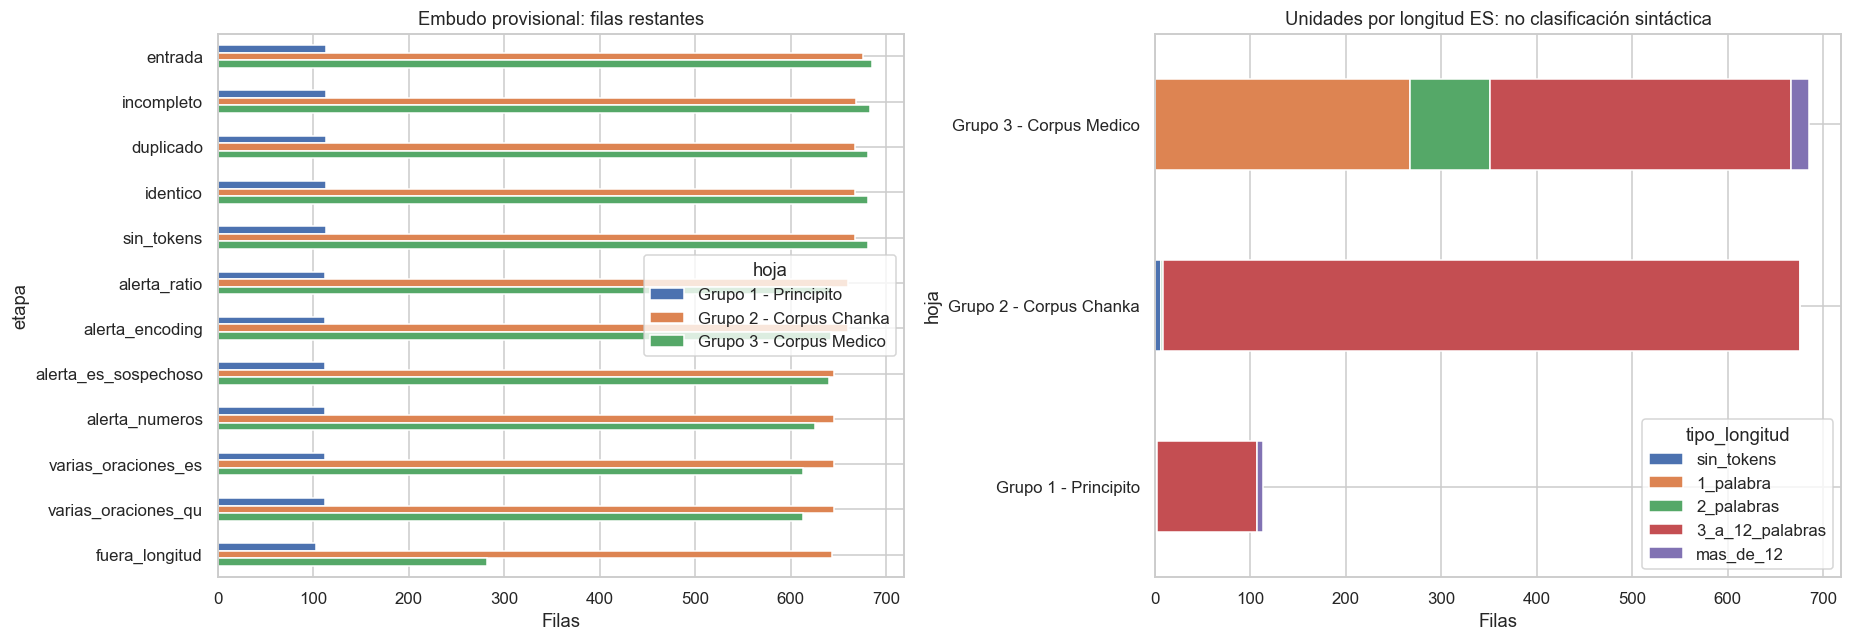

,par_id,Español,Quechua Chanka,alertas
90,Grupo 1 - Principito:fila_92,Adiós –le dijo a la flor.,"Fioramanmi nirqa: Chaynaqa, ripullaykichikyá , nispa.",alerta_ratio
140,Grupo 2 - Corpus Chanka:fila_29,¿Qué comiste hoy?,¿Imatam kunan punchaw mikurqanki?,alerta_ratio
178,Grupo 2 - Corpus Chanka:fila_67,Hoy no hay escuela.,Kunan punchaw yachaywasi mana kanchu.,alerta_ratio
180,Grupo 2 - Corpus Chanka:fila_69,Ellos están construyendo una casa.,Paykuna huk wasita rurachkanku.,alerta_es_sospechoso
182,Grupo 2 - Corpus Chanka:fila_71,Esta palabra es difícil.,Kay simi sasa.,alerta_ratio
197,Grupo 2 - Corpus Chanka:fila_86,Este camino es largo.,Kay ñan suni.,alerta_ratio
210,Grupo 2 - Corpus Chanka:fila_99,Aquí no se balea.,Kaypiqa mana balawan wañuchinachu.,alerta_ratio
326,Grupo 2 - Corpus Chanka:fila_215,ella no construye un puente.,Pay huk chakata mana ruranchu.,alerta_es_sospechoso
327,Grupo 2 - Corpus Chanka:fila_216,ella construye un puente.,Pay huk chakata ruran.,alerta_es_sospechoso
328,Grupo 2 - Corpus Chanka:fila_217,ellas no construen una casa.,Paykuna huk wasita mana rurankuchu.,alerta_es_sospechoso


In [38]:
ES, QU = 'Español', 'Quechua Chanka'
assert ES in IDIOMAS and QU in IDIOMAS, 'Esta ampliación requiere las dos columnas ES–Chanka.'
auditoria = pares_maestros.copy(deep=True)
auditoria = auditoria.merge(par[['hoja','fila_excel','ratio_car','atipico']],
    on=['hoja','fila_excel'],how='left',validate='one_to_one')
auditoria['ratio_evaluado'] = auditoria.atipico.notna()
auditoria['alerta_ratio'] = auditoria.atipico.fillna(False).astype(bool)
for lang, nombre in [(ES,'es'),(QU,'qu')]:
    textos = auditoria[lang].fillna('').astype(str)
    auditoria[f'tokens_{nombre}'] = textos.map(tokens_seleccion)
    auditoria[f'n_{nombre}'] = auditoria[f'tokens_{nombre}'].map(len)
    auditoria[f'numeros_{nombre}'] = textos.map(lambda t: sorted(re.findall(r'\d+(?:[.,]\d+)*',t)))
    auditoria[f'varias_oraciones_{nombre}'] = textos.str.contains(r'[.!?]\s+[A-ZÁÉÍÓÚÑ¿¡]',regex=True)
auditoria['clave_es'] = auditoria.tokens_es.map(' '.join)
auditoria['pregunta_es'] = auditoria[ES].fillna('').str.contains(r'[¿?]',regex=True)
auditoria['negacion_es'] = auditoria.tokens_es.map(lambda ts: bool(set(ts)&{'no','nunca','jamás','tampoco','sin'}))
auditoria['tipo_longitud'] = pd.cut(auditoria.n_es,[-1,0,1,2,12,np.inf],
    labels=['sin_tokens','1_palabra','2_palabras','3_a_12_palabras','mas_de_12'])
auditoria['alerta_encoding'] = (auditoria[ES].fillna('')+' '+auditoria[QU].fillna('')).str.contains(r'�|Ã|Â',regex=True)
auditoria['alerta_es_sospechoso'] = auditoria[ES].fillna('').str.contains(r'(?i)[bcdfghjklmnpqrstvwxyz]{4,}',regex=True)
auditoria['alerta_numeros'] = auditoria.numeros_es.ne(auditoria.numeros_qu)
auditoria['sin_tokens'] = auditoria.n_es.eq(0) | auditoria.n_qu.eq(0)
auditoria['fuera_longitud'] = ~auditoria.n_es.between(MIN_ES_SELECCION,MAX_ES_SELECCION) | ~auditoria.n_qu.between(1,MAX_QU_SELECCION)
REGLAS = ['incompleto','duplicado','identico','sin_tokens','alerta_ratio','alerta_encoding',
          'alerta_es_sospechoso','alerta_numeros','varias_oraciones_es','varias_oraciones_qu','fuera_longitud']
auditoria['alertas'] = auditoria[REGLAS].apply(lambda r:' | '.join(r.index[r]),axis=1)
auditoria['ruta_revision'] = np.select([
    auditoria.n_es.eq(0),auditoria.n_es.gt(0)&auditoria.n_qu.eq(0),auditoria.duplicado,
    auditoria[['alerta_ratio','alerta_encoding','alerta_es_sospechoso','identico']].any(axis=1)],
    ['revisar_fuente_sin_es','completar_traduccion','revisar_duplicado','revisar_texto_alineacion'],
    default='revisar_linguistica')
auditoria['candidato_preseleccion'] = ~auditoria[REGLAS].any(axis=1)
auditoria['estado'] = 'pendiente_revision'
for col in ['texto_es_aprobado','texto_qu_aprobado','alineacion_validada','chanka_validado',
    'autonomia_validada','revisor_id','motivo_decision','fuente_traduccion','hablante_id','archivo_audio']:
    auditoria[col] = ''

# Embudo ordenado, motivos solapables conservados en la tabla maestra.
embudo=[]
for hoja,g in auditoria.groupby('hoja',sort=False):
    mascara=pd.Series(True,index=g.index)
    embudo.append({'hoja':hoja,'etapa':'entrada','restantes':len(g),'apartados_en_paso':0})
    for regla in REGLAS:
        antes=int(mascara.sum()); mascara &= ~g[regla]
        embudo.append({'hoja':hoja,'etapa':regla,'restantes':int(mascara.sum()),'apartados_en_paso':antes-int(mascara.sum())})
embudo=pd.DataFrame(embudo)
display(auditoria.groupby('hoja')[REGLAS+['candidato_preseleccion']].sum())
fig,axes=plt.subplots(1,2,figsize=(17,6))
embudo.pivot(index='etapa',columns='hoja',values='restantes').reindex(['entrada']+REGLAS).plot.barh(ax=axes[0])
axes[0].set(title='Embudo provisional: filas restantes',xlabel='Filas'); axes[0].invert_yaxis()
pd.crosstab(auditoria.hoja,auditoria.tipo_longitud).plot.barh(stacked=True,ax=axes[1])
axes[1].set(title='Unidades por longitud ES: no clasificación sintáctica',xlabel='Filas')
plt.tight_layout(); fig.savefig(SALIDA/'01_auditoria.png',dpi=130); plt.show()
display(auditoria[auditoria.alerta_ratio|auditoria.alerta_es_sospechoso][['par_id',ES,QU,'alertas']].head(15))


## 16. Comparación léxica bajo condiciones equivalentes

Se complementan las tablas históricas sobre `tokens_lex` con tokens completos, incluidos números
y negación, en ambos idiomas. Para cada combinación idioma/hoja se toma el mismo número de tokens
contiguos de su secuencia concatenada, con 30 ventanas aleatorias y semilla fija. La media y los
percentiles muestran variación entre ventanas, **no intervalos de confianza independientes**.
La tokenización, la morfología y el dominio todavía afectan al TTR: no es una medida de calidad
de traducción ni una prueba de superioridad léxica de una lengua.


,idioma,hoja,tokens_completos,tipos_completos,ttr_completo,tokens_ventana,ttr_ventanas_media,p10_ventanas,p90_ventanas
0,Español,Grupo 1 - Principito,707,349,0.494,300,0.589,0.560,0.637
1,Español,Grupo 2 - Corpus Chanka,3393,542,0.160,300,0.302,0.173,0.560
2,Español,Grupo 3 - Corpus Medico,2429,945,0.389,300,0.633,0.490,0.867
3,Quechua Chanka,Grupo 1 - Principito,487,358,0.735,300,0.799,0.790,0.810
4,Quechua Chanka,Grupo 2 - Corpus Chanka,2605,663,0.255,300,0.344,0.220,0.599
5,Quechua Chanka,Grupo 3 - Corpus Medico,2105,1411,0.670,300,0.810,0.723,0.887


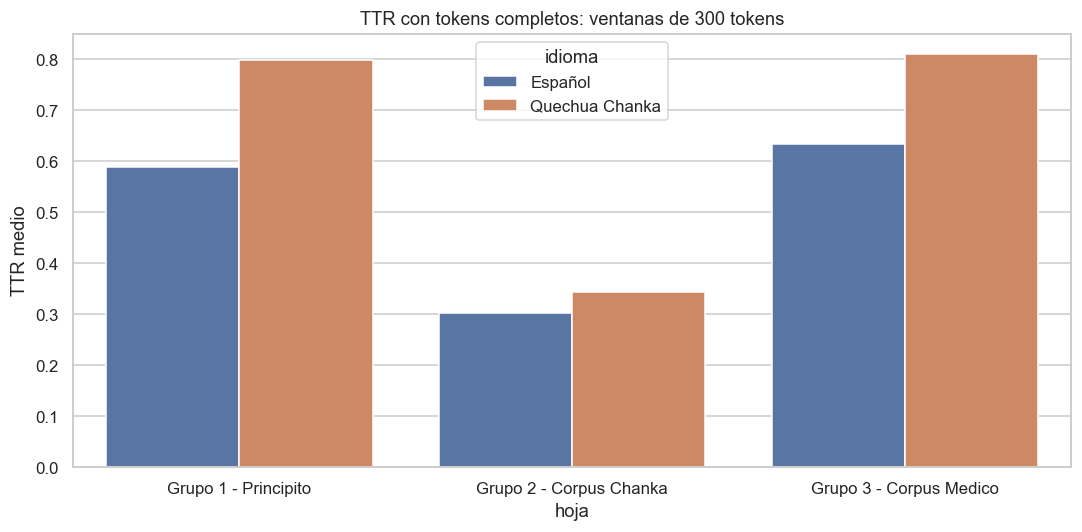

In [39]:
secuencias = {(i,h):[t for ts in g.tokens_seleccion for t in ts]
    for (i,h),g in corpus.groupby(['idioma','hoja'])}
positivas = [len(ts) for ts in secuencias.values() if ts]
assert positivas, 'No hay tokens para la comparación.'
N_IGUAL = min(300,min(positivas))
rng=np.random.default_rng(SEMILLA)
comparacion=[]
for (idioma,hoja),ts in secuencias.items():
    if not ts: continue
    valores=[]
    for _ in range(30):
        inicio=int(rng.integers(0,len(ts)-N_IGUAL+1))
        ventana=ts[inicio:inicio+N_IGUAL]
        valores.append(len(set(ventana))/N_IGUAL)
    comparacion.append({'idioma':idioma,'hoja':hoja,'tokens_completos':len(ts),
        'tipos_completos':len(set(ts)),'ttr_completo':len(set(ts))/len(ts),
        'tokens_ventana':N_IGUAL,'ttr_ventanas_media':np.mean(valores),
        'p10_ventanas':np.quantile(valores,.1),'p90_ventanas':np.quantile(valores,.9)})
comparacion=pd.DataFrame(comparacion)
display(comparacion)
fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(data=comparacion,x='hoja',y='ttr_ventanas_media',hue='idioma',ax=ax,errorbar=None)
ax.set(title=f'TTR con tokens completos: ventanas de {N_IGUAL} tokens',ylabel='TTR medio')
plt.tight_layout();fig.savefig(SALIDA/'02_ttr_comparable.png',dpi=130);plt.show()


## 17. Preselección equilibrada y cobertura de las flashcards

Objetivo inicial: hasta 300 pares para **revisar**, con español de 3–12 tokens y quechua de hasta
25 tokens. Es una configuración de prosa; las unidades cortas se conservan en otra hoja.
Se evita repetir el español normalizado, dejando las alternativas en la tabla maestra.

Se rota entre las fuentes con menos filas seleccionadas que aún tienen candidatos disponibles.
Dentro de cada fuente se maximiza el vocabulario de las flashcards principales todavía no
cubierto, con peso inverso a su frecuencia. Los empates se resuelven por cercanía a cinco
tokens y por ID. Cuando se agota el vocabulario nuevo, ese criterio de longitud ordena el resto.
No se trunca, adapta ni traduce ningún texto. La cobertura se mide sobre formas escritas,
no lemas, morfemas ni fonemas; compartir una palabra no demuestra alineación del par.

La curva se compara con selecciones aleatorias bajo el mismo orden de fuentes y la misma
restricción de español único. Se comparan solo tamaños alcanzados por todas las repeticiones.
La referencia guía la selección, por lo que la curva no es una evaluación independiente.


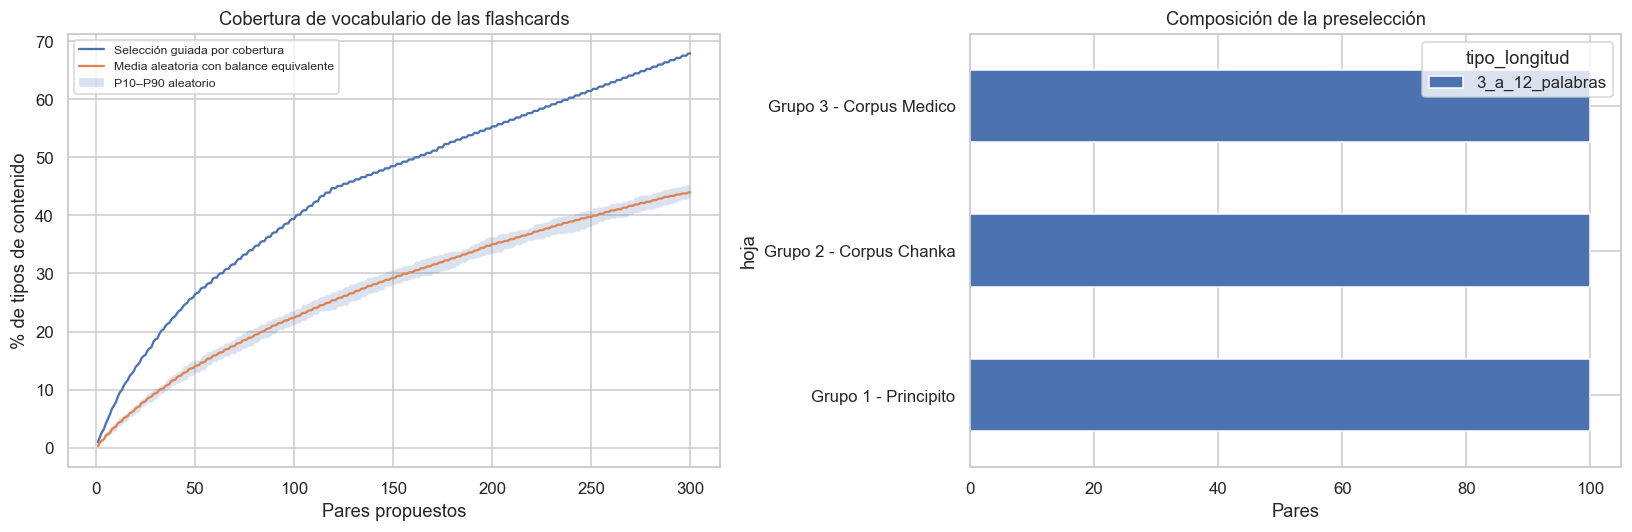

hoja
Grupo 1 - Principito       100
Grupo 2 - Corpus Chanka    100
Grupo 3 - Corpus Medico    100
Name: propuestos, dtype: int64

,orden_revision,codigo_original,Español,Quechua Chanka,palabras_nuevas
0,1,EL-0081,Hace mucho frío en tu tierra.,Llaqtaykipiqa anchata chirin.,5
1,2,F-0060,Los monos negros están en la cima del arbol.,Yana machinkuna sachapa puntanpi kachkanku.,5
2,3,112.0,En cada comida tienes que lavarte las manos.,Makiykita sapa mikunapi mayllijunayki.,4
3,4,EL-0049,Son árboles tan grandes como iglesias.,Iglesiakuna hina hatun sachakunam kanku.,3
4,5,F-0474,Yo duermo cinco horas al día.,Ñuqa sapa punchaw pichqa urata puñuni.,5
5,6,,¿Te cansas rápido cuando caminas?,purispaypi pisipanki utqayllamachu,4
6,7,EL-0071,"¡Eso no es un hombre, es un hongo!","¡Chayqa manam runachu, hongo kasqa!",4
7,8,F-0475,Tú duermes hasta tarde los sábados.,Qam sabadupi tardikama puñunki.,5
8,9,,¿Dónde vives ahora?,maypitaq kanan yachanki,3
9,10,EL-0085,Esta flor me hacía sentir desdichado.,Kay waytaqa llakisqa sientichiwaqmi.,3


Cobertura final: 67.87 %; aprobación lingüística pendiente.


In [40]:
referencia = pd.read_excel(RUTA_REFERENCIA,sheet_name='Sheet1')
assert 'TEXTO_SPA' in referencia
STOP_COBERTURA=set('el la los las un una unos unas de del a al en por para con y e o u que'.split())
def vocab_contenido(texto):
    return set(tokens_seleccion(texto))-STOP_COBERTURA
frecuencia_ref=Counter(t for s in referencia.TEXTO_SPA.dropna() for t in tokens_seleccion(s) if t not in STOP_COBERTURA)
objetivo=set(frecuencia_ref)
assert objetivo, 'Referencia sin vocabulario.'
pesos={t:1/(1+np.log1p(frecuencia_ref[t])) for t in objetivo}
candidatos=auditoria[auditoria.candidato_preseleccion].copy()
assert len(candidatos), 'No quedan candidatos; revisar reglas antes de ampliar selección.'
datos=candidatos.to_dict('index')
sets={i:vocab_contenido(s) for i,s in candidatos[ES].items()}
disponibles=set(candidatos.index); usados=set(); cubierto=set(); seleccion=[]; curva=[]; recuento=Counter()
orden_fuentes=list(dict_hojas)
for paso in range(min(N_SELECCION,len(candidatos))):
    validos=[i for i in sorted(disponibles) if datos[i]['clave_es'] not in usados]
    if not validos: break
    fuentes=set(candidatos.loc[validos,'hoja'])
    hoja=min(fuentes,key=lambda h:(recuento[h],orden_fuentes.index(h)))
    opciones=[i for i in validos if datos[i]['hoja']==hoja]
    def prioridad(i):
        nuevos=(sets[i]&objetivo)-cubierto
        return (-sum(pesos[t] for t in sorted(nuevos)),abs(datos[i]['n_es']-5),datos[i]['par_id'])
    elegido=min(opciones,key=prioridad)
    nuevos=(sets[elegido]&objetivo)-cubierto
    cubierto |= sets[elegido]&objetivo
    seleccion.append(elegido);recuento[hoja]+=1;disponibles.remove(elegido)
    usados.add(candidatos.loc[elegido,'clave_es'])
    curva.append({'n':len(seleccion),'hoja':hoja,'par_id':candidatos.loc[elegido,'par_id'],
        'palabras_nuevas':len(nuevos),'vocab_nuevo':' | '.join(sorted(nuevos)),
        'cobertura_pct':100*len(cubierto)/len(objetivo)})
curva=pd.DataFrame(curva)
preseleccion=candidatos.loc[seleccion].copy()
preseleccion.insert(0,'orden_revision',np.arange(1,len(preseleccion)+1))
preseleccion=preseleccion.merge(curva[['par_id','palabras_nuevas','vocab_nuevo']],on='par_id',validate='one_to_one')
rng=np.random.default_rng(SEMILLA)
aleatorias=[]
for repeticion in range(REPETICIONES_COBERTURA):
    ids=set(candidatos.index);claves=set();cub=set();valores=[]
    for hoja in curva.hoja:
        opciones=[i for i in sorted(ids) if datos[i]['hoja']==hoja and datos[i]['clave_es'] not in claves]
        if not opciones: break
        i=int(rng.choice(opciones));ids.remove(i);claves.add(datos[i]['clave_es']);cub |= sets[i]&objetivo
        valores.append(100*len(cub)/len(objetivo))
    aleatorias.append(valores)
n_comun=min(map(len,aleatorias))
azar=np.array([v[:n_comun] for v in aleatorias])
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes[0].plot(curva.n,curva.cobertura_pct,label='Selección guiada por cobertura')
if n_comun:
    xs=np.arange(1,n_comun+1)
    axes[0].plot(xs,azar.mean(axis=0),label='Media aleatoria con balance equivalente')
    axes[0].fill_between(xs,np.quantile(azar,.1,axis=0),np.quantile(azar,.9,axis=0),alpha=.2,label='P10–P90 aleatorio')
    curva.loc[:n_comun-1,'azar_media_pct']=azar.mean(axis=0)
axes[0].set(title='Cobertura de vocabulario de las flashcards',xlabel='Pares propuestos',ylabel='% de tipos de contenido');axes[0].legend(fontsize=8)
pd.crosstab(preseleccion.hoja,preseleccion.tipo_longitud).plot.barh(stacked=True,ax=axes[1])
axes[1].set(title='Composición de la preselección',xlabel='Pares')
plt.tight_layout();fig.savefig(SALIDA/'03_cobertura.png',dpi=130);plt.show()
vocab_candidatos=set().union(*sets.values()) if sets else set()
cobertura_vocab=pd.DataFrame([{'palabra':t,'frecuencia_referencia':frecuencia_ref[t],
    'disponible_en_candidatos':t in vocab_candidatos,'cubierta_en_seleccion':t in cubierto} for t in sorted(objetivo)])
display(preseleccion.groupby('hoja').size().rename('propuestos'))
display(preseleccion[['orden_revision','codigo_original',ES,QU,'palabras_nuevas']].head(12))
print('Cobertura final:',round(100*len(cubierto)/len(objetivo),2),'%; aprobación lingüística pendiente.')


## 18. Diversidad observable y revisión humana

Las preguntas se detectan por signos y la negación por un listado español. Son indicadores
solapables y no una clasificación exhaustiva de estructuras. Personas y tiempos requieren
análisis contextual; no se infieren del conteo de pronombres. No se asigna variedad Chanka
automáticamente por rasgos superficiales ni se elimina ortografía sin revisión de hablantes.

Se revisa una muestra tanto de candidatos como de apartados (hasta 15 por fuente y condición),
además del piloto. No hay gráfico de calidad humana todavía: todas las filas están pendientes.
Tras anotar, reportar aprobados/corregidos/rechazados con el número revisado por fuente.


,pares,preguntas,con_negacion,mediana_tokens_es
hoja,,,,
Grupo 1 - Principito,100,10,18,6.000
Grupo 2 - Corpus Chanka,100,3,11,5.000
Grupo 3 - Corpus Medico,100,53,9,5.000


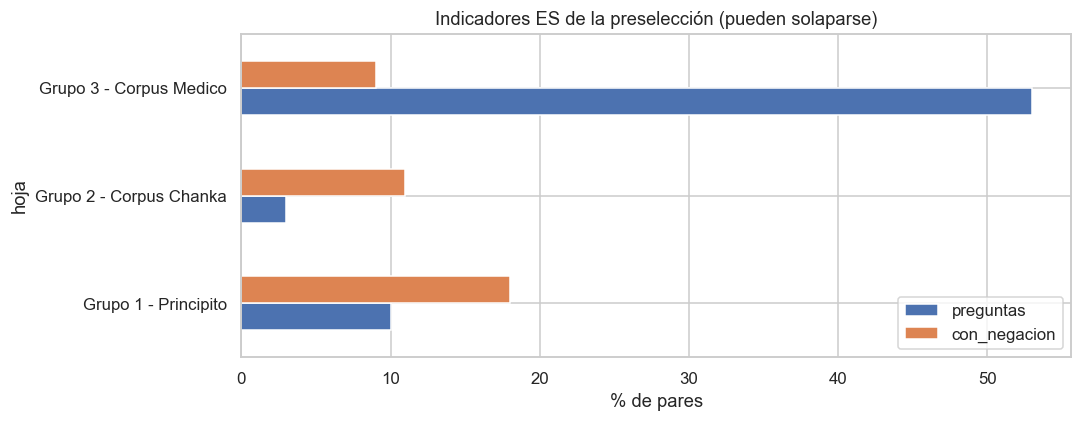

In [41]:
diversidad=preseleccion.groupby('hoja').agg(pares=('par_id','size'),preguntas=('pregunta_es','sum'),
    con_negacion=('negacion_es','sum'),mediana_tokens_es=('n_es','median'))
display(diversidad)
fig,ax=plt.subplots(figsize=(10,4))
diversidad[['preguntas','con_negacion']].div(diversidad.pares,axis=0).mul(100).plot.barh(ax=ax)
ax.set(title='Indicadores ES de la preselección (pueden solaparse)',xlabel='% de pares')
plt.tight_layout();fig.savefig(SALIDA/'04_diversidad.png',dpi=130);plt.show()
muestra_auditoria=pd.concat([g.sample(min(15,len(g)),random_state=SEMILLA)
    for _,g in auditoria.groupby(['hoja','candidato_preseleccion'])],ignore_index=True)


## 19. Exportación de revisión y controles

Abrir **`revision_corpus.xlsx`** en la carpeta de esta ejecución. `preseleccion` es una cola de
revisión, no un corpus validado. `maestro` conserva todas las entradas; `alertas` agrupa los
casos señalados; `completar_traduccion` recupera español sin quechua; `unidades_cortas` permite
revisar vocabulario fuera del objetivo de prosa. `muestra_auditoria` incluye apartados.

No hay descartes ni aprobaciones automáticos. No se reutiliza un archivo previamente anotado:
cada ejecución genera su carpeta. Las copias entre hojas y CSV no se sincronizan; elegir una
hoja de trabajo y consolidar después por `par_id`. Ese ID localiza la fila en esta versión;
el hash del Excel identifica la versión. Si se reordena el origen, hay que remapear los IDs.


In [42]:
from openpyxl.styles import Alignment
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation
def tabla_exportable(df):
    cols=[c for c in df.columns if not c.startswith('tokens_') and not c.endswith('__norm')]
    out=df[cols].copy()
    for c in ['numeros_es','numeros_qu']:
        if c in out: out[c]=out[c].map(lambda v:' | '.join(v))
    frente=[c for c in ['orden_revision','par_id','codigo_original','hoja','fila_excel',
        ES+'__original',QU+'__original','estado','alertas','ruta_revision','texto_es_aprobado','texto_qu_aprobado'] if c in out]
    return out[frente+[c for c in out if c not in frente]]
guia=pd.DataFrame([
    ['estado','pendiente_revision / corregir / descartado / aprobado_para_grabar'],
    ['aprobacion','Solo humana: validar equivalencia, naturalidad, autonomía y variedad Chanka'],
    ['originales','No sobrescribir; registrar cambios en texto_es_aprobado y texto_qu_aprobado'],
    ['alertas','Son heurísticas, no errores confirmados ni reglas de exclusión definitiva'],
    ['traducciones','Registrar fuente_traduccion y revisor_id; sin inferir origen o corrección por la etiqueta'],
    ['copias','Elegir una hoja para editar: las otras hojas y CSV no se sincronizan'],
    ['numeros','Revisar equivalencia y lectura de cantidades; números escritos en letras pueden generar alertas'],
    ['grabacion','Completar hablante_id y archivo_audio después de la validación'],
    ['particiones','Si se entrena un modelo de voz, controlar hablantes y variantes de frases entre particiones']
],columns=['campo','instruccion'])
tablas={'preseleccion':tabla_exportable(preseleccion),'maestro':tabla_exportable(auditoria),
    'alertas':tabla_exportable(auditoria[auditoria.alertas.ne('')]),
    'completar_traduccion':tabla_exportable(auditoria[auditoria.ruta_revision.eq('completar_traduccion')]),
    'unidades_cortas':tabla_exportable(auditoria[auditoria.n_es.between(1,2)]),
    'muestra_auditoria':tabla_exportable(muestra_auditoria),'embudo':embudo,'cobertura_vocab':cobertura_vocab,
    'curva_cobertura':curva,'ttr_comparable':comparacion,'diversidad':diversidad.reset_index(),'instrucciones':guia}
excel_revision=SALIDA/'revision_corpus.xlsx'
with pd.ExcelWriter(excel_revision,engine='openpyxl') as writer:
    for nombre,df in tablas.items():
        df.to_excel(writer,sheet_name=nombre,index=False)
        df.to_csv(SALIDA/f'{nombre}.csv',index=False,encoding='utf-8-sig')
        ws=writer.book[nombre];ws.freeze_panes='F2';ws.auto_filter.ref=ws.dimensions
        for j,c in enumerate(df.columns,1):
            ws.column_dimensions[get_column_letter(j)].width=55 if c.endswith('__original') or c.startswith('texto_') else 23
        for fila in ws.iter_rows():
            for celda in fila:
                celda.alignment=Alignment(wrap_text=True,vertical='top')
                if isinstance(celda.value,str) and celda.value.startswith('='):celda.data_type='s'
        if 'estado' in df and len(df):
            dv=DataValidation(type='list',formula1='"pendiente_revision,corregir,descartado,aprobado_para_grabar"')
            dv.errorTitle='Estado no válido';dv.error='Elegir un estado de la lista';dv.showErrorMessage=True
            ws.add_data_validation(dv);col=get_column_letter(df.columns.get_loc('estado')+1);dv.add(f'{col}2:{col}{len(df)+1}')

assert len(auditoria)==sum(len(d) for d in dict_hojas.values())
assert auditoria.par_id.is_unique
assert not preseleccion.clave_es.duplicated().any()
assert preseleccion.candidato_preseleccion.all()
assert auditoria.estado.eq('pendiente_revision').all()
assert preseleccion.texto_qu_aprobado.eq('').all()
assert len(preseleccion)<=N_SELECCION
assert curva.cobertura_pct.is_monotonic_increasing
assert tokens_seleccion('No tomes 2 tabletas.')==['no','tomes','2','tabletas']
assert tokens_seleccion("ch'aki ñan") == ["ch'aki",'ñan']
for row in auditoria.to_dict('records'):
    fuente=dict_hojas[row['hoja']].iloc[int(row['fila_excel'])-2]
    for idioma in IDIOMAS:
        a,b=row[idioma+'__original'],fuente[idioma]
        assert (pd.isna(a) and pd.isna(b)) or a==b
    assert row['codigo_original']==('' if pd.isna(fuente.get('N°','')) else str(fuente.get('N°','')))
for p,digest in inventario_entrada.items():assert hashlib.sha256(Path(p).read_bytes()).hexdigest()==digest
comprobado=pd.read_excel(excel_revision,sheet_name='maestro')
assert len(comprobado)==len(auditoria)
assert comprobado.par_id.tolist()==auditoria.par_id.tolist()
resumen_auditoria={'archivo_corpus':RUTA_EXCEL,'hashes_entrada':inventario_entrada,
    'filas_maestras':len(auditoria),'pares_para_eda':len(pares),'alertas_ratio':int(auditoria.alerta_ratio.sum()),
    'candidatos_automaticos':len(candidatos),'preseleccion':len(preseleccion),
    'seleccion_por_fuente':preseleccion.hoja.value_counts().to_dict(),
    'completar_traduccion':int(auditoria.ruta_revision.eq('completar_traduccion').sum()),
    'vocab_objetivo':len(objetivo),'vocab_cubierto':len(cubierto),'cobertura_pct':100*len(cubierto)/len(objetivo),
    'aprobados_automaticamente':0,'salida':str(SALIDA),'excel_revision':str(excel_revision),
    'parametros':{'n_seleccion':N_SELECCION,'min_es':MIN_ES_SELECCION,'max_es':MAX_ES_SELECCION,
        'max_qu':MAX_QU_SELECCION,'repeticiones_azar':REPETICIONES_COBERTURA,'semilla':SEMILLA},
    'entorno':{'python':platform.python_version(),**{p:version(p) for p in ['pandas','numpy','scikit-learn','nltk','seaborn','openpyxl']}}}
(SALIDA/'resumen.json').write_text(json.dumps(resumen_auditoria,ensure_ascii=False,indent=2),encoding='utf-8')
(SALIDA.parent/'ultima_ejecucion.json').write_text(json.dumps(resumen_auditoria,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.Series({k:v for k,v in resumen_auditoria.items() if isinstance(v,(int,float))}))
print('Controles superados. Excel para revisión:',excel_revision)


filas_maestras              1,474.000
pares_para_eda              1,461.000
alertas_ratio                  47.000
candidatos_automaticos      1,028.000
preseleccion                  300.000
completar_traduccion            2.000
vocab_objetivo                526.000
vocab_cubierto                357.000
cobertura_pct                  67.871
aprobados_automaticamente       0.000
dtype: float64

Controles superados. Excel para revisión: resultados_vibe\revision_20261013T234825_221182Z\revision_corpus.xlsx
